In [1]:
import numpy as np
import pandas as pd
import itertools
import matplotlib.pyplot as plt
from matplotlib import cm
from datetime import date
import re
from tqdm import tqdm
import time
# from pybedtools import BedTool
import random
import math
import pickle
import seaborn as sns
from scipy.stats import percentileofscore, pearsonr, rankdata, fisher_exact, describe, hypergeom
from scipy.spatial.distance import jaccard, euclidean, cosine, pdist, squareform
import functools
import operator
import gzip
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from scipy.cluster import hierarchy
import sys
import os
from functools import partial
from contextlib import closing
from multiprocessing import Pool
import re
import h5py
from collections import Counter
# from region_comparison_combine_scores_CT20220810 import combine_scores
from operator import is_not

today = date.today()

In [2]:
def kde_wrapper(data, bw=0.1):
    fig = plt.figure()
    fig.patch.set_facecolor('white')
    
    sns.kdeplot(data, bw_adjust=bw)
    print(describe(data))
    return fig

**Counts -> Sigmoid scale**

In [ ]:
count_path='/home/ctrader/region_similarity/data/count_based/regions_25kb_CT20221027.DHScounts.hdf5'

In [ ]:
#load the data
count_hdf5 = h5py.File(count_path, 'r')
count_arr = count_hdf5['base_arr'][:]
count_hdf5.close()

In [4]:
dhs = []
f = open('/home/ctrader/region_similarity/data/regions_25kb_CT20220815.DHSmapped.bed', 'r')
comp_names = f.readline().strip().split('\t')[3:]
f.close()

Text(-0.02, 0.48, 'Region Count')

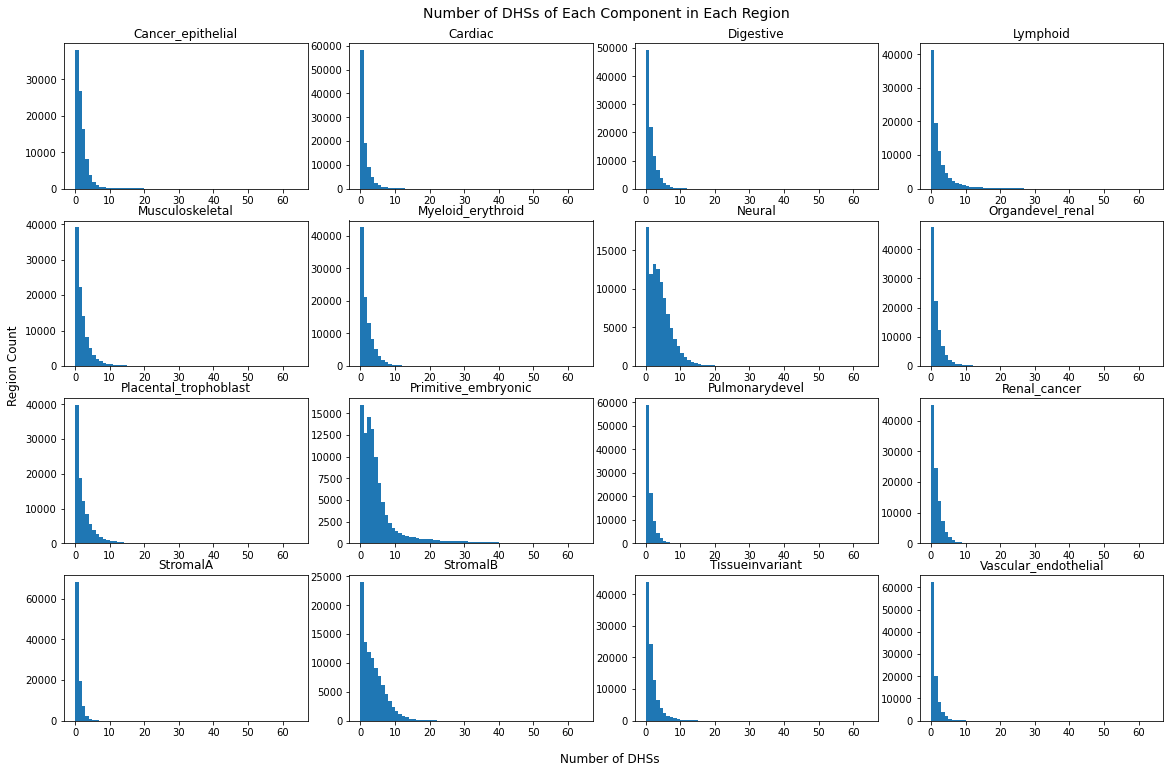

In [5]:
fig, axes = plt.subplots(nrows=4, ncols=4, figsize=(16, 10))
fig.patch.set_facecolor('white')
fig.tight_layout()

axes = axes.ravel()

max_count = np.max(count_arr)

for i, ax, comp in zip(range(16), axes, comp_names):
    ax.hist(count_arr[:, i], bins=np.arange(max_count+1))
    ax.set_title(comp)
    
fig.suptitle('Number of DHSs of Each Component in Each Region', y=1.03, fontsize=14)
fig.text(0.46, -0.02, 'Number of DHSs', fontsize=12)
fig.text(-0.02, 0.48, 'Region Count', fontsize=12, rotation=90)

In [31]:
#rank each region based on counts
ranked_counts = rankdata(count_arr, axis=0)

In [32]:
ranked_counts

array([[18990. , 29086.5, 24618.5, ..., 12000. , 21939. , 31214. ],
       [18990. , 29086.5, 24618.5, ..., 12000. , 21939. , 31214. ],
       [18990. , 29086.5, 24618.5, ..., 30828.5, 21939. , 31214. ],
       ...,
       [18990. , 29086.5, 24618.5, ..., 12000. , 21939. , 31214. ],
       [18990. , 29086.5, 24618.5, ..., 12000. , 21939. , 31214. ],
       [18990. , 29086.5, 24618.5, ..., 12000. , 21939. , 31214. ]])

In [33]:
#limit component ranks to just ragions with at least 1 DHS of that component
ranked_counts = np.where(count_arr==0, 0, ranked_counts)

In [34]:
ranked_counts

array([[    0. ,     0. ,     0. , ...,     0. ,     0. ,     0. ],
       [    0. ,     0. ,     0. , ...,     0. ,     0. ,     0. ],
       [    0. ,     0. ,     0. , ..., 30828.5,     0. ,     0. ],
       ...,
       [    0. ,     0. ,     0. , ...,     0. ,     0. ,     0. ],
       [    0. ,     0. ,     0. , ...,     0. ,     0. ,     0. ],
       [    0. ,     0. ,     0. , ...,     0. ,     0. ,     0. ]])

In [35]:
ranked_counts.shape

(98629, 16)

In [12]:
np.count_nonzero(ranked_counts)/16

55362.5

Text(0.5, 1.0, 'Comparing Scaling Factors for Sigmoid Function')

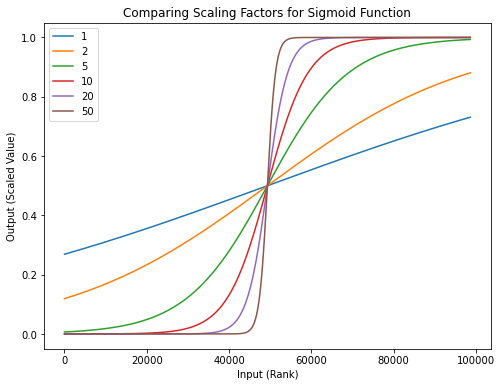

In [62]:
def sigmoid_func(arr, scaling_factor=5):
    num_regions = len(arr)
    x = (arr / (num_regions / (scaling_factor * 2))) - scaling_factor
    sig_arr = 1 / (1 + np.exp(-x))
    return sig_arr

fig = plt.figure(figsize=(8, 6))
fig.patch.set_facecolor('white')

sf = [1, 2, 5, 10, 20, 50]
for i in sf:
    t = sigmoid_func(np.arange(len(ranked_counts)), scaling_factor=i)
    plt.plot(t)

plt.legend(sf)
plt.xlabel('Input (Rank)')
plt.ylabel('Output (Scaled Value)')
plt.title('Comparing Scaling Factors for Sigmoid Function')

In [77]:
#ordering DHS colors
DHS_comps_paper = np.array(['Placental / trophoblast', 'Lymphoid', 'Myeloid / erythroid', 'Cardiac', 
                            'Musculoskeletal', 'Vascular / endothelial', 'Primitive / embryonic', 
                            'Neural', 'Digestive', 'Stromal A', 'Stromal B', 'Renal / cancer', 
                            'Cancer / epithelial', 'Pulmonary devel.', 'Organ devel. / renal', 
                            'Tissue invariant'])

DHS_color = np.array(['#FFE500', '#FE8102', '#FF0000', '#07AF00', '#4C7D14', '#414613', '#05C1D9', '#0467FD', 
                      '#009588', '#BB2DD4', '#7A00FF', '#4A6876', '#08245B', '#B9461D', '#692108', '#C3C3C3'])

DHS_color = DHS_color[np.argsort(DHS_comps_paper)]

Text(0.5, 1.0, 'Sigmoid Values for Regional DHS Ranks')

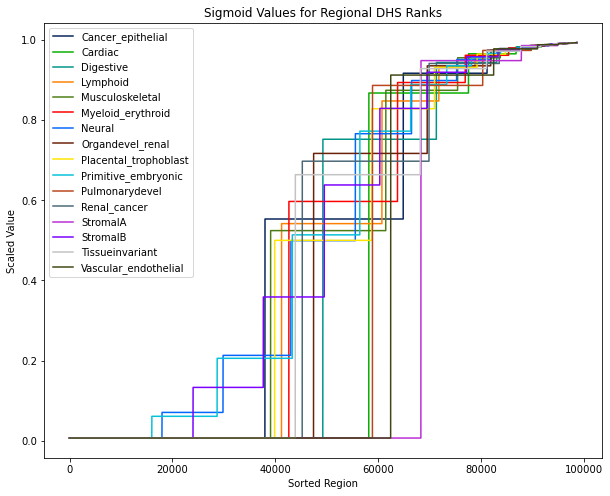

In [15]:
fig = plt.figure(figsize=(10, 8))
fig.patch.set_facecolor('white')


for i, comp, c in zip(range(16), comp_names, DHS_color):
    t = sigmoid_func(np.sort(ranked_counts[:, i]))
    plt.plot(t, color=c)

plt.legend(comp_names)
plt.ylabel('Scaled Value')
plt.xlabel('Sorted Region')
plt.title('Sigmoid Values for Regional DHS Ranks')

In [84]:
#sigmoid of rank for all regions
sigmoid_ranks = sigmoid_func(ranked_counts)

In [80]:
x = np.array([0, 0, 0, 1, 1, 1, 1, 4, 21, 4, 12, 2, 3, 0])
num_0 = len(x) - np.count_nonzero(x)

ranks = rankdata(x) - num_0
ranks = np.where(ranks < 0, 0, ranks)
print(ranks)
print(rankdata(x, method='dense'))
print(rankdata(x) - num_0)

[ 0.   0.   0.   2.5  2.5  2.5  2.5  7.5 10.   7.5  9.   5.   6.   0. ]
[1 1 1 2 2 2 2 5 7 5 6 3 4 1]
[-1.5 -1.5 -1.5  2.5  2.5  2.5  2.5  7.5 10.   7.5  9.   5.   6.  -1.5]


In [18]:
print(rank_regions(x))

[ 0.   0.   0.   2.5  2.5  2.5  2.5  7.5 10.   7.5  9.   5.   6.   0. ]


In [20]:
print(rank_regions_2(x))

[0.  0.  0.  1.  1.  1.  1.  6.  8.5 6.  7.5 3.5 4.5 0. ]


In [29]:
print(rank_regions_3(x))

[0 0 0 1 1 1 1 4 6 4 5 2 3 0]


In [16]:
def rank_regions(arr):
    #for epilogos scores, setting negative values to 0
    arr = np.where(arr < 0, 0, arr)
    
    #rank each region based on counts
    ranked_regions = rankdata(arr, axis=0)
    
    #find the number of regions with 0 values for each component
    comp_num_zero = len(arr) - np.count_nonzero(arr, axis=0)
    
    #adjusting/resetting ranks
    ranked_regions = ranked_regions - comp_num_zero
    ranked_regions = np.where(ranked_regions < 0, 0, ranked_regions)
    
    return ranked_regions

# ranked_regions = rank_regions(count_arr)

In [19]:
def rank_regions_2(arr):
    #for epilogos scores, setting negative values to 0
    arr = np.where(arr < 0, 0, arr)
    
    #rank each region based on counts
    ranked_regions = rankdata(arr, axis=0)
    
    #find the number of regions with 0 values for each component
    comp_num_zero = len(arr) - np.count_nonzero(arr, axis=0)
    
    #adjusting/resetting ranks
    ranked_regions = ranked_regions - comp_num_zero
    
    
    
    ####setting first rank to 1. Or just use "dense" ranking???
    ranked_regions = np.where(ranked_regions < 0, -len(arr), ranked_regions)
    #finding the mininmum resulting rank
    adjusted_min = np.min(np.abs(ranked_regions), axis=0) - 1
    #resetting ranks
    ranked_regions = ranked_regions - adjusted_min
    ranked_regions = np.where(ranked_regions < 0, 0, ranked_regions)
    
    
    return ranked_regions

ranked_regions_2 = rank_regions_2(count_arr)

In [27]:
def rank_regions_3(arr):
    #for epilogos scores, setting negative values to 0
    arr = np.where(arr < 0, 0, arr)
    
    #rank each region based on counts
    ranked_regions = rankdata(arr, axis=0, method='dense')
    
    #find the number of regions with 0 values for each component
    comp_num_zero = len(arr) - np.count_nonzero(arr, axis=0)
    adjustment = np.where(comp_num_zero > 0, 1, 0)
    
    #adjusting/resetting ranks
    ranked_regions = ranked_regions - adjustment
    
    return ranked_regions

ranked_regions_3 = rank_regions_3(count_arr)

In [135]:
ranked_regions

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 1., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])

In [117]:
np.unique(ranked_regions, axis=0)

array([[-18989. , -29085.5, -24617.5, ..., -11999. , -21938. , -31213. ],
       [-18989. , -29085.5, -24617.5, ..., -11999. , -21938. ,  10012.5],
       [-18989. , -29085.5, -24617.5, ..., -11999. , -21938. ,  24292. ],
       ...,
       [ 60648.5, -29085.5, -24617.5, ...,   6829.5, -21938. , -31213. ],
       [ 60648.5, -29085.5,  42188. , ...,  61588. ,  12151.5, -31213. ],
       [ 60650. ,   9693. , -24617.5, ...,  30915. ,  12151.5,  10012.5]])

In [35]:
np.count_nonzero(ranked_regions, axis=0) - np.max(ranked_regions, axis=0)

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])

In [38]:
np.count_nonzero(ranked_regions_2, axis=0)

array([60650, 40457, 49393, 57425, 59553, 55998, 80668, 51196, 58764,
       82645, 39745, 53397, 30325, 74630, 54752, 36202])

In [37]:
np.max(ranked_regions_2, axis=0)

array([47205. , 30765. , 38357.5, 47664. , 48355. , 45435. , 74734. ,
       40148.5, 49315. , 76296. , 29025.5, 41073.5, 20561. , 67801.5,
       42601.5, 26190.5])

In [55]:
print(np.max(sigmoid_func_2(ranked_regions)))

print(np.max(sigmoid_func_2(ranked_regions_2)))

print(np.max(sigmoid_func_2(ranked_regions_3)))

0.9933071490757153
0.9933071490757153
0.9933071490757153


In [48]:
print(np.max(ranked_regions, axis=0))
print(np.count_nonzero(ranked_regions, axis=0))
print()
print(np.max(ranked_regions_2, axis=0))
print(np.count_nonzero(ranked_regions_2, axis=0))
print()
print(np.max(ranked_regions_3, axis=0))
print(np.count_nonzero(ranked_regions_3, axis=0))

[60650. 40457. 49393. 57425. 59553. 55998. 80668. 51196. 58764. 82645.
 39745. 53397. 30325. 74630. 54752. 36202.]
[60650 40457 49393 57425 59553 55998 80668 51196 58764 82645 39745 53397
 30325 74630 54752 36202]

[47205.  30765.  38357.5 47664.  48355.  45435.  74734.  40148.5 49315.
 76296.  29025.5 41073.5 20561.  67801.5 42601.5 26190.5]
[60650 40457 49393 57425 59553 55998 80668 51196 58764 82645 39745 53397
 30325 74630 54752 36202]

[41 41 29 48 40 36 49 36 42 60 21 33 23 46 26 26]
[60650 40457 49393 57425 59553 55998 80668 51196 58764 82645 39745 53397
 30325 74630 54752 36202]


In [73]:
print(np.min(ranked_regions_3, axis=0))

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [15]:
def sigmoid_func_2(ranked_arr, scaling_factor=5):

    #max rank
    max_rank = np.max(ranked_arr, axis=0)
    
    #scaling between [-scaling_factor, scaling_factor]
    x = (ranked_arr / (max_rank / (scaling_factor * 2))) - scaling_factor
    sig_arr = 1 / (1 + np.exp(-x))
    return sig_arr

# sigmoid_ranks = sigmoid_func_2(ranked_regions)

Text(0.5, 1.0, 'Sigmoid Values for Adjusted Regional DHS Ranks')

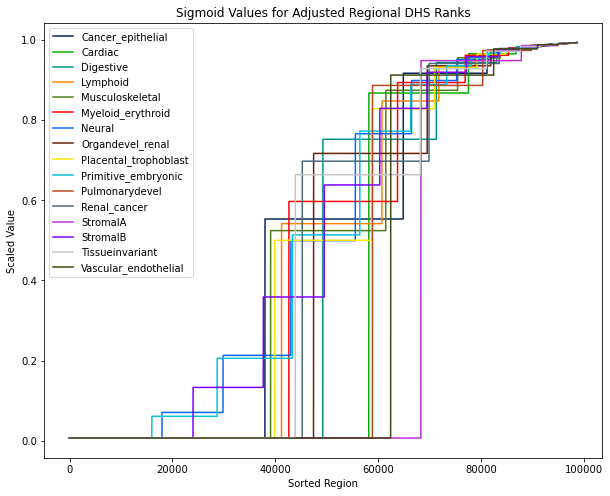

In [75]:
fig = plt.figure(figsize=(10, 8))
fig.patch.set_facecolor('white')

ranked_counts = rankdata(count_arr, axis=0)
ranked_counts = np.where(count_arr==0, 0, ranked_counts)

test = sigmoid_func_2(np.sort(ranked_counts, axis=0))

for i, comp, c in zip(range(16), comp_names, DHS_color):
    t = test[:, i]
    plt.plot(t, color=c)

plt.legend(comp_names)
plt.ylabel('Scaled Value')
plt.xlabel('Sorted Region')
plt.title('Sigmoid Values for Adjusted Regional DHS Ranks')

Text(-0.02, 0.48, 'Region Count')

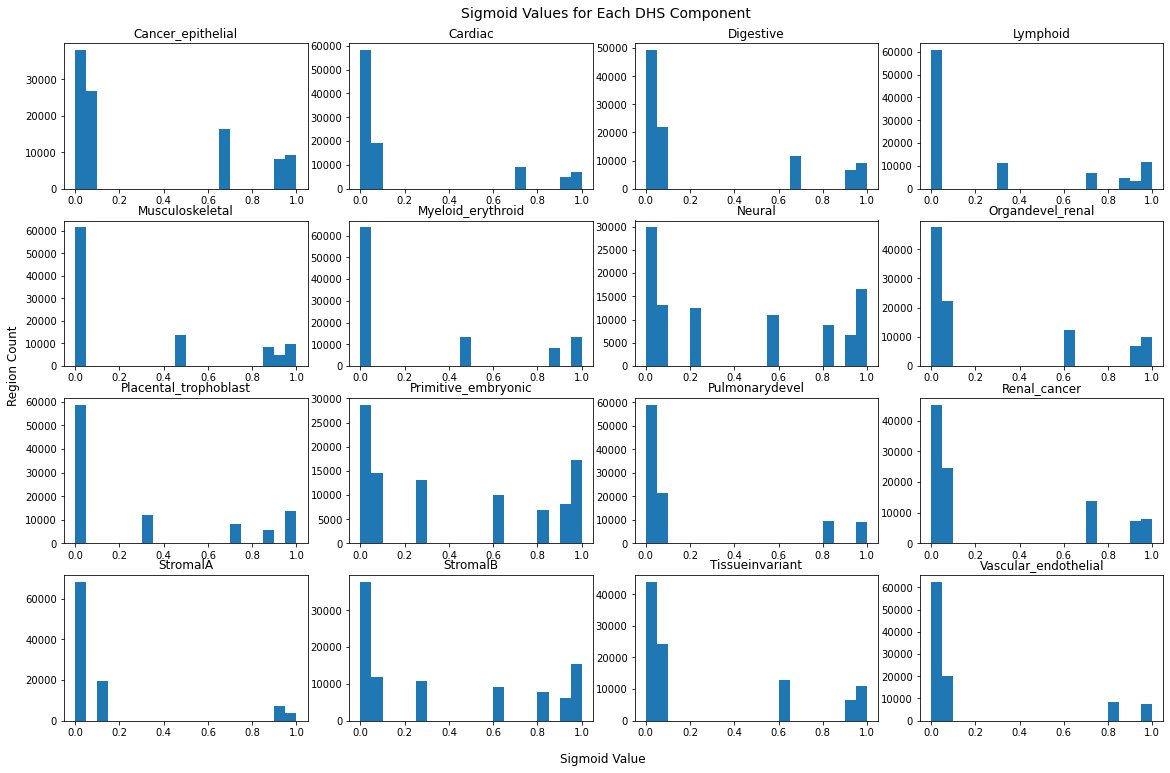

In [28]:
fig, axes = plt.subplots(nrows=4, ncols=4, figsize=(16, 10))
fig.patch.set_facecolor('white')
fig.tight_layout()

axes = axes.ravel()

max_count = np.max(count_arr)

for i, ax, comp in zip(range(16), axes, comp_names):
    ax.hist(sigmoid_ranks[:, i], bins=np.arange(0, 1.05, 0.05))
    ax.set_title(comp)
    
fig.suptitle('Sigmoid Values for Each DHS Component', y=1.03, fontsize=14)
fig.text(0.46, -0.02, 'Sigmoid Value', fontsize=12)
fig.text(-0.02, 0.48, 'Region Count', fontsize=12, rotation=90)

Text(0.5, 1.0, 'Sigmoid Values for Adjusted Regional DHS Ranks')

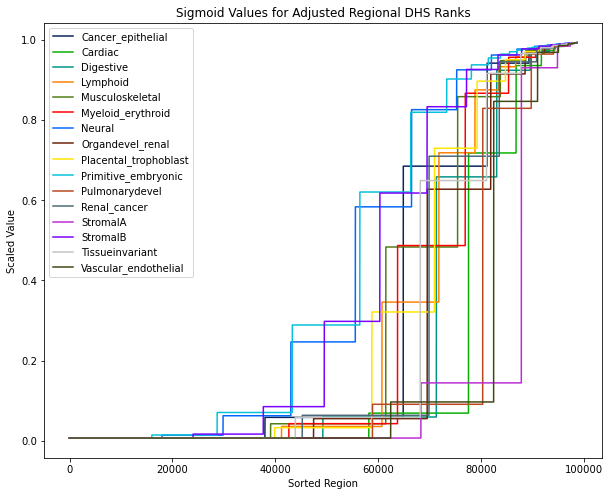

In [76]:
####will use this one

fig = plt.figure(figsize=(10, 8))
fig.patch.set_facecolor('white')

test = sigmoid_func_2(np.sort(ranked_regions, axis=0))

for i, comp, c in zip(range(16), comp_names, DHS_color):
    t = test[:, i]
    plt.plot(t, color=c)

plt.legend(comp_names)
plt.ylabel('Scaled Value')
plt.xlabel('Sorted Region')
plt.title('Sigmoid Values for Adjusted Regional DHS Ranks')

Text(0.5, 1.0, 'Sigmoid Values for Adjusted Regional DHS Ranks')

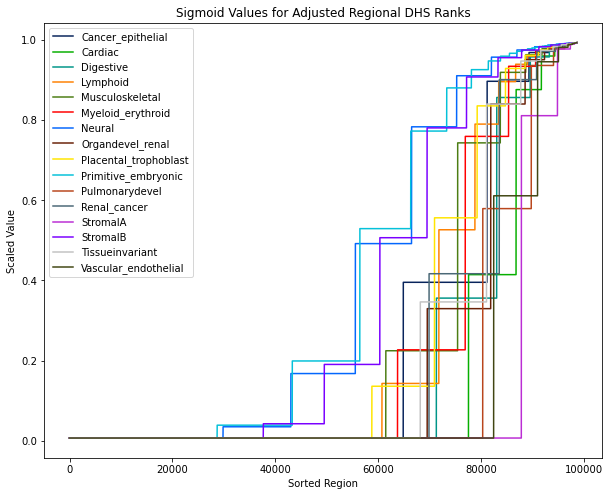

In [77]:
fig = plt.figure(figsize=(10, 8))
fig.patch.set_facecolor('white')

test = sigmoid_func_2(np.sort(ranked_regions_2, axis=0))

for i, comp, c in zip(range(16), comp_names, DHS_color):
    t = test[:, i]
    plt.plot(t, color=c)

plt.legend(comp_names)
plt.ylabel('Scaled Value')
plt.xlabel('Sorted Region')
plt.title('Sigmoid Values for Adjusted Regional DHS Ranks')

Text(0.5, 1.0, 'Sigmoid Values for Adjusted Regional DHS Ranks')

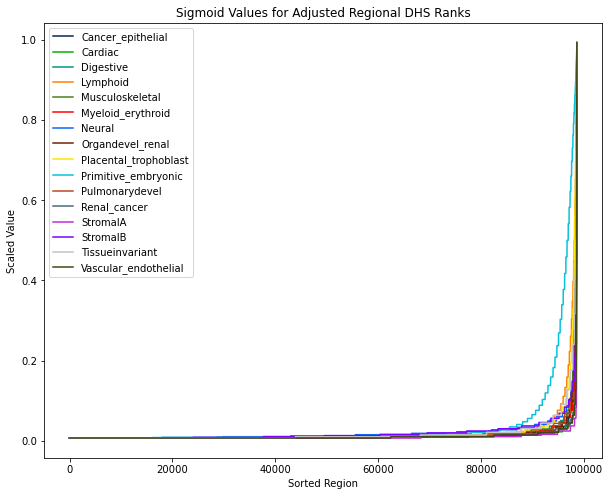

In [78]:
fig = plt.figure(figsize=(10, 8))
fig.patch.set_facecolor('white')

test = sigmoid_func_2(np.sort(ranked_regions_3, axis=0))

for i, comp, c in zip(range(16), comp_names, DHS_color):
    t = test[:, i]
    plt.plot(t, color=c)

plt.legend(comp_names)
plt.ylabel('Scaled Value')
plt.xlabel('Sorted Region')
plt.title('Sigmoid Values for Adjusted Regional DHS Ranks')

In [45]:
np.max(distance_m)

3.697880129221868

**Euclidean Distance**

In [36]:
#euclidean distance matrix
distance_m = squareform(pdist(sigmoid_ranks[:10000], metric='euclidean'))

In [38]:
#find the max distance
max_distance = np.max(distance_m)

In [15]:
# #sim matrix
# sim_m = max_distance - distance_m

In [102]:
#sim matrix
sim_m = 1 - (distance_m / max_distance)

In [90]:
np.min(sim_m)

0.0

In [103]:
#regions with 0 DHSs
dhs_per_region = np.sum(count_arr, axis=1)
regions_0_DHSs = np.where(dhs_per_region==0)[0]

#for now...
regions_0_DHSs = regions_0_DHSs[regions_0_DHSs<10000]

In [104]:
#setting similarity values in regions with no DHSs to 0
sim_m[regions_0_DHSs] = 0
sim_m[:, regions_0_DHSs] = 0

In [39]:
max_distance

3.697880129221868

In [19]:
np.max(sim_m)

3.8158296747427056

In [114]:
np.min(top_vals_all)

0.0

In [112]:
#top 1000 regions and values
def find_top_regions(sim_m):
    top_regions_all = []
    top_vals_all = []
    for i in range(len(sim_m)):
        top_regions = np.argsort(-sim_m[i])[:1001]
        top_regions = top_regions[top_regions!=i][:1000]
        top_regions_all.append(top_regions)
        top_vals_all.append(sim_m[i, top_regions])
    top_regions_all = np.array(top_regions_all)
    top_vals_all = np.array(top_vals_all)
    return top_regions_all, top_vals_all
top_regions_all, top_vals_all = find_top_regions(sim_m)

In [65]:
np.argsort(-distance_m[i])

array([7767, 7037,  338, ..., 1700, 6879, 9999])

In [44]:
def scale_data(data, max_poss):
    data_to_rank = data[data!=0]
    max_obs = np.max(data_to_rank)
    rank_data = rankdata(data_to_rank, method='average')
    rank_data = rank_data/(len(data_to_rank))
    rank_data = rank_data * max_obs/max_poss

    original_data_shape = data.shape
    data = data.astype(float).flatten()
    np.put(data, np.where(data!=0)[0], rank_data)
    data = data.reshape(original_data_shape)
    return data
# top_scaled_vals = scale_data(top_vals_all, max_distance)

**DHS Similarities**

In [49]:
#load the data
sigmoideuc_path = '/home/ctrader/region_similarity/data/rank_based/regions_25kb_CT20221101.DHSsigmoideuc.hdf5'
sigmoideuc_hdf5 = h5py.File(sigmoideuc_path, 'r')
top_1000_scaled_vals = sigmoideuc_hdf5['top_1000_scaled_vals'][:]
top_1000_similar_regions = sigmoideuc_hdf5['top_1000_similar_regions'][:]
sigmoideuc_hdf5.close()

In [18]:
top_1000_similar_regions[1][-1]

37438

In [2]:
f = open('/home/ctrader/region_similarity/data/Altius_25kb_hg38_maxMean_CT20220815.c1t3.bed', 'r')
regions = f.readlines()
f.close()

In [8]:
print(regions[1].strip().split('\t'))
print('chr1:46800-71800')

['chr1', '46800', '71800']
chr1:46800-71800


In [10]:
print(regions[37438].strip().split('\t'))
print('chr18:19185800-19210800')

['chr18', '19185800', '19210800']
chr18:19185800-19210800


In [41]:
print(count_arr[1])
print(ranked_regions[1])
print(sigmoid_ranks[1])

[0 0 0 0 0 0 1 0 1 1 0 0 0 0 0 0]
[   0.    0.    0.    0.    0.    0. 5935.    0. 9450. 6350.    0.    0.
    0.    0.    0.    0.]
[0.00669285 0.00669285 0.00669285 0.00669285 0.00669285 0.00669285
 0.01386715 0.00669285 0.03255043 0.0143203  0.00669285 0.00669285
 0.00669285 0.00669285 0.00669285 0.00669285]


In [42]:
print(count_arr[37438])
print(ranked_regions[37438])
print(sigmoid_ranks[37438])

[1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
[13446.     0.     0.     0.     0.     0.     0.     0.     0.     0.
     0.     0.     0.     0.     0.     0.]
[0.05824882 0.00669285 0.00669285 0.00669285 0.00669285 0.00669285
 0.00669285 0.00669285 0.00669285 0.00669285 0.00669285 0.00669285
 0.00669285 0.00669285 0.00669285 0.00669285]


In [24]:
# top_1000_similar_regions[37438]
# top_1000_scaled_vals[37438]

In [41]:
1 - pdist([sigmoid_ranks[37438], sigmoid_ranks[1]]) / max_distance

array([0.98414773])

In [46]:
pdist([np.ones(16), np.zeros(16)])

array([4.])

In [23]:
np.where(top_1000_scaled_vals[:, 0]==0)[0].shape

(8023,)

Text(0.5, 1.0, 'Top 1000 DHS Similarity Values for Region 1')

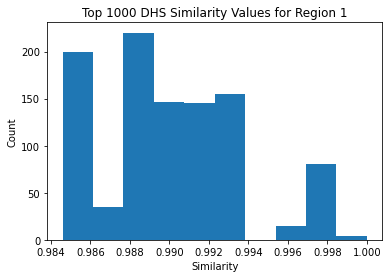

In [61]:
fig = plt.figure()
fig.patch.set_facecolor('white')

plt.hist(top_1000_scaled_vals[1])


plt.xlabel('Similarity')
plt.ylabel('Count')
plt.title('Top 1000 DHS Similarity Values for Region 1')

In [46]:
np.min(top_1000_scaled_vals[non_zero_regions])

0.4582943063038195

array([0.98458564, 0.98332002, 0.88890457, ..., 0.57171671, 0.58065922,
       0.63952693])

Text(0.5, 1.0, '1000th DHS Similarity Values for All* Regions')

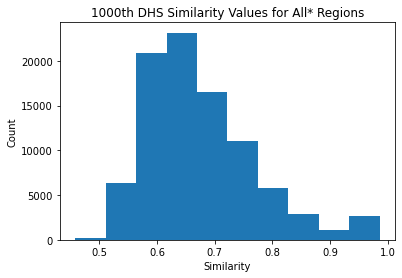

In [15]:
non_zero_regions = np.where(top_1000_scaled_vals[:, 0]!=0)[0]

fig = plt.figure()
fig.patch.set_facecolor('white')

plt.hist(top_1000_scaled_vals[non_zero_regions][:, -1])


plt.xlabel('Similarity')
plt.ylabel('Count')
plt.title('1000th DHS Similarity Values for All* Regions')

Text(0.5, 1.0, 'Top 1000 DHS Similarity Values for All* Regions')

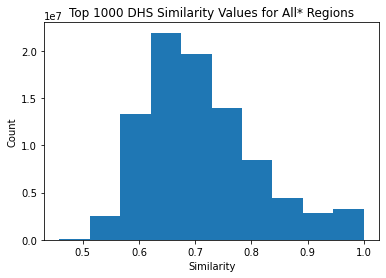

In [12]:
fig = plt.figure()
fig.patch.set_facecolor('white')

plt.hist(top_1000_scaled_vals[non_zero_regions].flatten())


plt.xlabel('Similarity')
plt.ylabel('Count')
plt.title('Top 1000 DHS Similarity Values for All* Regions')

Text(0.5, 1.04, 'Top 1000 DHS Motif Rescaled Similarity Values for All Regions')

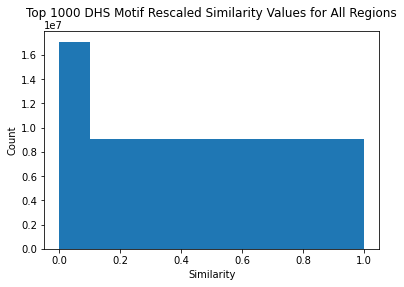

In [68]:
top_1000_rescaled_vals = scale_data(top_1000_scaled_vals, 1)
non_zero_regions = np.where(top_1000_rescaled_vals[:, 0]!=0)[0]

fig = plt.figure()
fig.patch.set_facecolor('white')

plt.hist(top_1000_rescaled_vals.flatten())


plt.xlabel('Similarity')
plt.ylabel('Count')
plt.title('Top 1000 DHS Motif Rescaled Similarity Values for All Regions', y=1.04)

Text(0.5, 1.0, 'Smaller Average Similarity Scores for Regions with More DHSs')

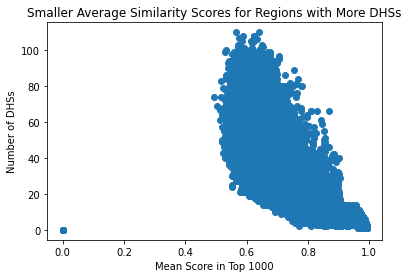

In [106]:
average_top1000_per_region = np.mean(top_1000_scaled_vals, axis=1)
num_dhs_per_region = np.sum(count_arr, axis=1)

fig = plt.figure()
fig.patch.set_facecolor('white')

plt.scatter(average_top1000_per_region, num_dhs_per_region)


plt.xlabel('Mean Score in Top 1000')
plt.ylabel('Number of DHSs')
plt.title('Smaller Average Similarity Scores for Regions with More DHSs')

In [81]:
sigmoid_ranks.shape

(98629, 16)

Text(0, 0.5, 'Max Scaled Similarity Value')

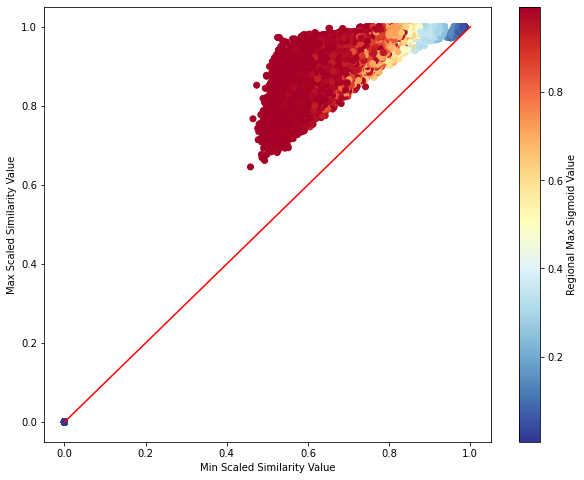

In [86]:
sigmoid_ranks_max = np.max(sigmoid_ranks, axis=1)

min_top1000_per_region = np.min(top_1000_scaled_vals, axis=1)
max_top1000_per_region = np.max(top_1000_scaled_vals, axis=1)

cm = plt.cm.get_cmap('RdYlBu_r')

fig = plt.figure(figsize=(10, 8))
fig.patch.set_facecolor('white')

s = plt.scatter(min_top1000_per_region, max_top1000_per_region, c=sigmoid_ranks_max, cmap=cm)
plt.plot([0, 1], [0, 1], color='r')
plt.colorbar(s).set_label('Regional Max Sigmoid Value')


plt.xlabel('Min Scaled Similarity Value')
plt.ylabel('Max Scaled Similarity Value')
# plt.title('DHS Before Sigmoid Scaling')

In [13]:
top_1000_similar_regions.shape[1]

1000

In [9]:
sigmoid_ranks_max = np.max(sigmoid_ranks, axis=1)
max_sigmoid_a = np.vstack([sigmoid_ranks_max]*1000).T
max_sigmoid_b = sigmoid_ranks_max[top_1000_similar_regions]
max_sigmoid_to_scale = (max_sigmoid_a + max_sigmoid_b) / 2
top_1000_sigmoid_scaled_vals = top_1000_scaled_vals * max_sigmoid_to_scale

In [26]:
sigmoideuc_path = '/home/ctrader/region_similarity/data/rank_based/regions_25kb_CT20221101.DHSsigmoideuc.hdf5'
sigmoideuc_hdf5 = h5py.File(sigmoideuc_path, 'r')
DHS_top_1000_sigmoid_scaled_vals = sigmoideuc_hdf5['top_1000_sigmoid_scaled_vals'][:]
DHS_sigmoid_ranks = sigmoideuc_hdf5['sigmoid_ranks'][:]
sigmoideuc_hdf5.close()

Text(0.5, 1.0, 'DHS Sigmoid Scaled Values')

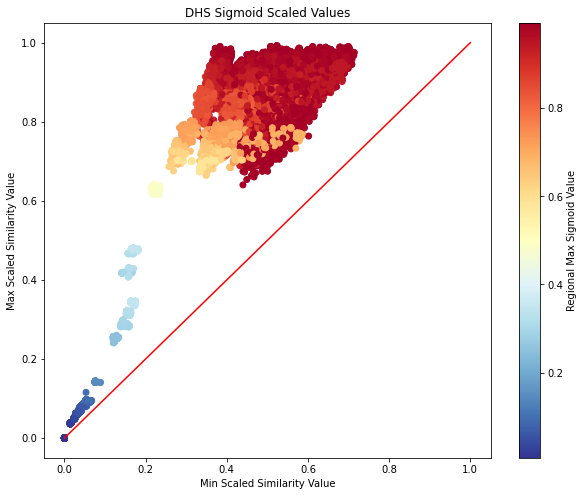

In [29]:
DHS_sigmoid_ranks_max = np.max(DHS_sigmoid_ranks, axis=1)

DHS_min_top1000_per_region = np.min(DHS_top_1000_sigmoid_scaled_vals, axis=1)
DHS_max_top1000_per_region = np.max(DHS_top_1000_sigmoid_scaled_vals, axis=1)

cm = plt.cm.get_cmap('RdYlBu_r')

fig = plt.figure(figsize=(10, 8))
fig.patch.set_facecolor('white')

s = plt.scatter(DHS_min_top1000_per_region, DHS_max_top1000_per_region, c=DHS_sigmoid_ranks_max, cmap=cm)
plt.plot([0, 1], [0, 1], color='r')
plt.colorbar(s).set_label('Regional Max Sigmoid Value')


plt.xlabel('Min Scaled Similarity Value')
plt.ylabel('Max Scaled Similarity Value')
plt.title('DHS Sigmoid Scaled Values')

Text(0.5, 1.0, 'Top Sigmoid Scaled DHS Similarity Score for each Region')

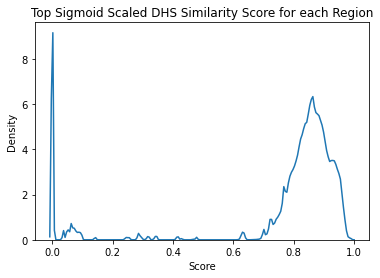

In [30]:
fig = plt.figure()
fig.patch.set_facecolor('white')

sns.kdeplot(DHS_max_top1000_per_region, bw_adjust=0.1)

plt.xlabel('Score')
plt.title('Top Sigmoid Scaled DHS Similarity Score for each Region')

In [2]:
sigmoideuc_path = '/home/ctrader/region_similarity/data/rank_based/regions_25kb_CT20221101.DHSsigmoideuc.hdf5'
sigmoideuc_hdf5 = h5py.File(sigmoideuc_path, 'r')
# DHS_top_1000_sigmoid_scaled_vals = sigmoideuc_hdf5['top_1000_sigmoid_scaled_vals'][:]
DHS_sigmoid_ranks = sigmoideuc_hdf5['sigmoid_ranks'][:]
sigmoideuc_hdf5.close()

In [58]:
DHS_sigmoid_ranks_max = np.max(DHS_sigmoid_ranks, axis=1)
DHS_top_1000_sigmoid_scaled_vals_rescaled = scale_data(DHS_top_1000_sigmoid_scaled_vals, 1)

Text(0.5, 1.0, 'DHS Sigmoid Scaled Values Rescaled')

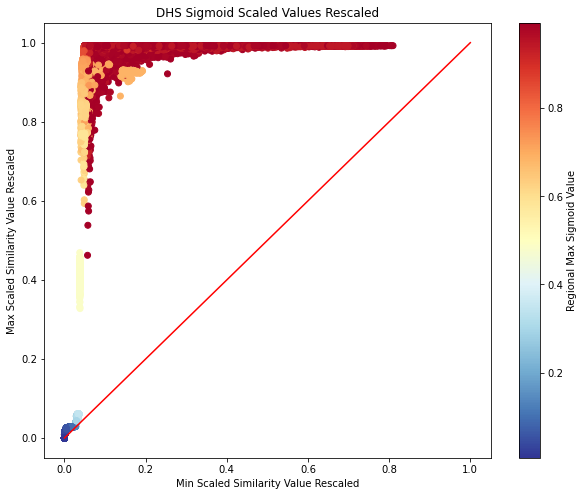

In [59]:
min_top1000_per_region = np.min(DHS_top_1000_sigmoid_scaled_vals_rescaled, axis=1)
max_top1000_per_region = np.max(DHS_top_1000_sigmoid_scaled_vals_rescaled, axis=1)

cm = plt.cm.get_cmap('RdYlBu_r')

fig = plt.figure(figsize=(10, 8))
fig.patch.set_facecolor('white')

s = plt.scatter(min_top1000_per_region, max_top1000_per_region, c=DHS_sigmoid_ranks_max, cmap=cm)
plt.plot([0, 1], [0, 1], color='r')
plt.colorbar(s).set_label('Regional Max Sigmoid Value')


plt.xlabel('Min Scaled Similarity Value Rescaled')
plt.ylabel('Max Scaled Similarity Value Rescaled')
plt.title('DHS Sigmoid Scaled Values Rescaled')

**TF Motifs**

In [23]:
#load the data
sigmoideuc_path = '/home/ctrader/region_similarity/data/rank_based/regions_25kb_CT20221027.TFsigmoideuc.hdf5'
sigmoideuc_hdf5 = h5py.File(sigmoideuc_path, 'r')
TF_top_1000_scaled_vals = sigmoideuc_hdf5['top_1000_scaled_vals'][:]
TF_top_1000_similar_regions = sigmoideuc_hdf5['top_1000_similar_regions'][:]
sigmoideuc_hdf5.close()

Text(0.5, 1.04, 'Top 1000 TF Motif Similarity Values for Region 1')

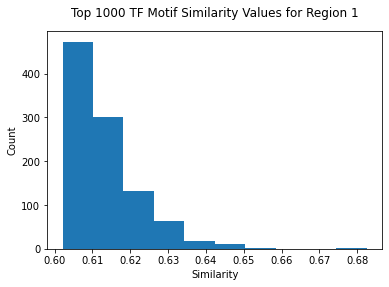

In [62]:
fig = plt.figure()
fig.patch.set_facecolor('white')

plt.hist(TF_top_1000_scaled_vals[1])


plt.xlabel('Similarity')
plt.ylabel('Count')
plt.title('Top 1000 TF Motif Similarity Values for Region 1', y=1.04)

Text(0.5, 1.04, 'Top 1000 TF Motif Similarity Values for All* Regions')

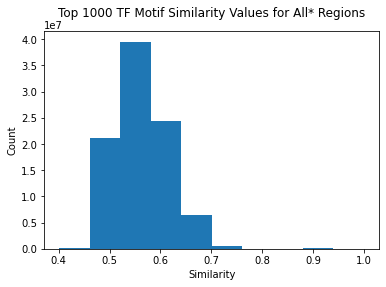

In [51]:
non_zero_regions = np.where(TF_top_1000_scaled_vals[:, 0]!=0)[0]

fig = plt.figure()
fig.patch.set_facecolor('white')

plt.hist(TF_top_1000_scaled_vals[non_zero_regions].flatten())


plt.xlabel('Similarity')
plt.ylabel('Count')
plt.title('Top 1000 TF Motif Similarity Values for All* Regions', y=1.04)

Text(0.5, 1.04, 'Top 1000 TF Motif Rescaled Similarity Values for All Regions')

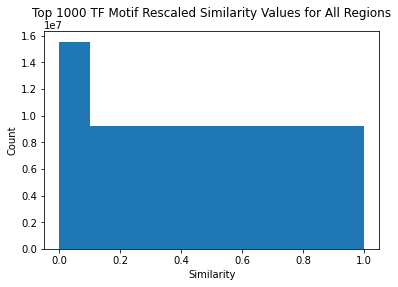

In [66]:
TF_top_1000_rescaled_vals = scale_data(TF_top_1000_scaled_vals, 1)
non_zero_regions = np.where(TF_top_1000_rescaled_vals[:, 0]!=0)[0]

fig = plt.figure()
fig.patch.set_facecolor('white')

plt.hist(TF_top_1000_rescaled_vals.flatten())


plt.xlabel('Similarity')
plt.ylabel('Count')
plt.title('Top 1000 TF Motif Rescaled Similarity Values for All Regions', y=1.04)

In [64]:
TF_top_1000_rescaled_vals.shape

(98629, 1000)

In [213]:
count_path='/home/ctrader/region_similarity/data/rank_based/regions_25kb_CT20221101.TFcounts.hdf5'

#load the data
count_hdf5 = h5py.File(count_path, 'r')
TF_count_arr = count_hdf5['base_arr'][:]
count_hdf5.close()

In [25]:
TF_ranked_regions = rank_regions(TF_count_arr)
TF_sigmoid_ranks = sigmoid_func_2(TF_ranked_regions)

In [26]:
TF_sigmoid_ranks_max = np.max(TF_sigmoid_ranks, axis=1)

In [27]:
TF_max_sigmoid_a = np.vstack([TF_sigmoid_ranks_max]*1000).T
TF_max_sigmoid_b = TF_sigmoid_ranks_max[TF_top_1000_similar_regions]

TF_max_sigmoid_to_scale = (TF_max_sigmoid_a + TF_max_sigmoid_b) / 2
TF_top_1000_sigmoid_scaled_vals = TF_top_1000_scaled_vals * TF_max_sigmoid_to_scale

In [23]:
sigmoideuc_path = '/home/ctrader/region_similarity/data/rank_based/regions_25kb_CT20221101.TFsigmoideuc.hdf5'
sigmoideuc_hdf5 = h5py.File(sigmoideuc_path, 'r')
TF_top_1000_sigmoid_scaled_vals = sigmoideuc_hdf5['top_1000_sigmoid_scaled_vals'][:]
TF_sigmoid_ranks = sigmoideuc_hdf5['sigmoid_ranks'][:]
sigmoideuc_hdf5.close()

Text(0.5, 1.0, 'TF Motif Sigmoid Scaled Values')

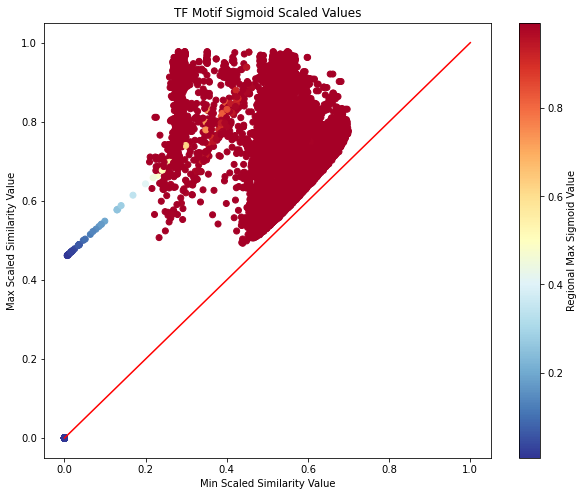

In [24]:
TF_sigmoid_ranks_max = np.max(TF_sigmoid_ranks, axis=1)

TF_min_top1000_per_region = np.min(TF_top_1000_sigmoid_scaled_vals, axis=1)
TF_max_top1000_per_region = np.max(TF_top_1000_sigmoid_scaled_vals, axis=1)

cm = plt.cm.get_cmap('RdYlBu_r')

fig = plt.figure(figsize=(10, 8))
fig.patch.set_facecolor('white')

s = plt.scatter(TF_min_top1000_per_region, TF_max_top1000_per_region, c=TF_sigmoid_ranks_max, cmap=cm)
plt.plot([0, 1], [0, 1], color='r')
plt.colorbar(s).set_label('Regional Max Sigmoid Value')


plt.xlabel('Min Scaled Similarity Value')
plt.ylabel('Max Scaled Similarity Value')
plt.title('TF Motif Sigmoid Scaled Values')

Text(0.5, 1.0, 'Top Sigmoid Scaled TF Motif Similarity Score for each Region')

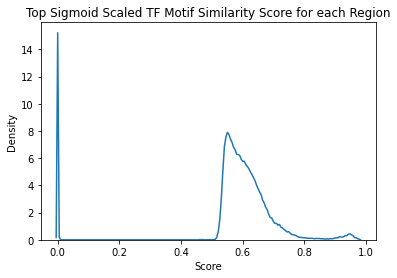

In [25]:
fig = plt.figure()
fig.patch.set_facecolor('white')

sns.kdeplot(TF_max_top1000_per_region, bw_adjust=0.1)

plt.xlabel('Score')
plt.title('Top Sigmoid Scaled TF Motif Similarity Score for each Region')

In [71]:
sigmoideuc_path = '/home/ctrader/region_similarity/data/rank_based/regions_25kb_CT20221101.TFsigmoideuc.hdf5'
sigmoideuc_hdf5 = h5py.File(sigmoideuc_path, 'r')
TF_top_1000_sigmoid_scaled_vals = sigmoideuc_hdf5['top_1000_sigmoid_scaled_vals'][:]
TF_sigmoid_ranks = sigmoideuc_hdf5['sigmoid_ranks'][:]
sigmoideuc_hdf5.close()

In [72]:
TF_sigmoid_ranks_max = np.max(TF_sigmoid_ranks, axis=1)
TF_top_1000_sigmoid_scaled_vals_rescaled = scale_data(TF_top_1000_sigmoid_scaled_vals, 1)

Text(0.5, 1.0, 'TF Motif Sigmoid Scaled Values Rescaled')

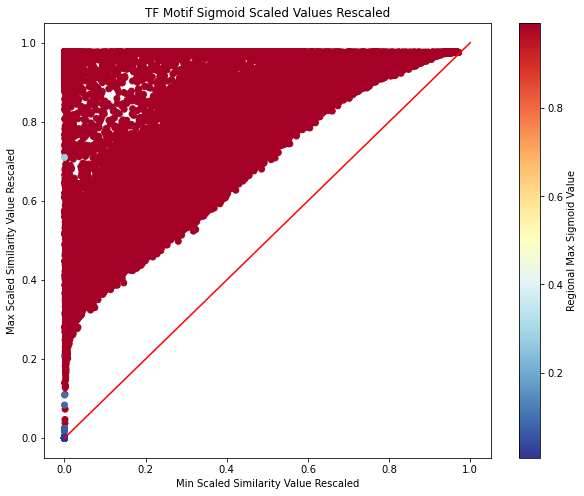

In [73]:
min_top1000_per_region = np.min(TF_top_1000_sigmoid_scaled_vals_rescaled, axis=1)
max_top1000_per_region = np.max(TF_top_1000_sigmoid_scaled_vals_rescaled, axis=1)

cm = plt.cm.get_cmap('RdYlBu_r')

fig = plt.figure(figsize=(10, 8))
fig.patch.set_facecolor('white')

s = plt.scatter(min_top1000_per_region, max_top1000_per_region, c=TF_sigmoid_ranks_max, cmap=cm)
plt.plot([0, 1], [0, 1], color='r')
plt.colorbar(s).set_label('Regional Max Sigmoid Value')


plt.xlabel('Min Scaled Similarity Value Rescaled')
plt.ylabel('Max Scaled Similarity Value Rescaled')
plt.title('TF Motif Sigmoid Scaled Values Rescaled')

**Chromatin States**

In [206]:
count_path='/home/ctrader/region_similarity/data/rank_based/regions_25kb_CT20221101.epilogosmeanmax.hdf5'
#load the data
count_hdf5 = h5py.File(count_path, 'r')
epi_count_arr = count_hdf5['base_arr'][:]
count_hdf5.close()

In [5]:
# #rank each region based on counts
# epi_ranked_counts = rankdata(epi_count_arr, axis=0)

Text(0.5, 1.0, 'Sigmoid Values for Regional CS Ranks')

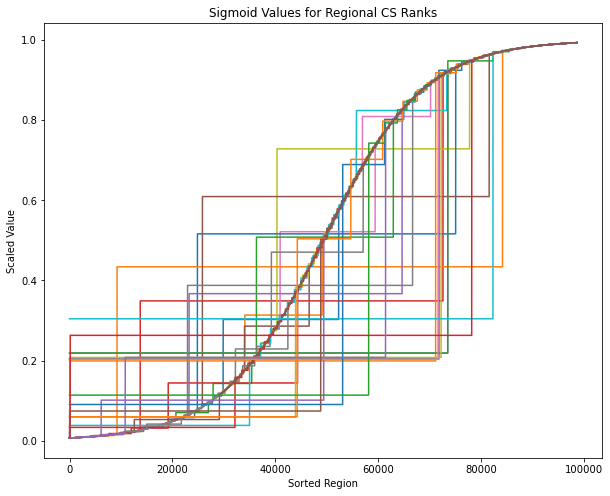

In [135]:
fig = plt.figure(figsize=(10, 8))
fig.patch.set_facecolor('white')


for i in range(36):
    t = sigmoid_func(np.sort(ranked_counts[:, i]))
    plt.plot(t)

plt.ylabel('Scaled Value')
plt.xlabel('Sorted Region')
plt.title('Sigmoid Values for Regional CS Ranks')

In [136]:
#sigmoid of rank for all regions
sigmoid_ranks = sigmoid_func(ranked_counts)

In [137]:
#euclidean distance matrix
distance_m = squareform(pdist(sigmoid_ranks[:10000], metric='euclidean'))

In [138]:
#find the max distance
max_distance = np.max(distance_m)

In [139]:
max_distance

5.330072559839385

In [140]:
#sim matrix
sim_m = max_distance - distance_m

In [153]:
count_arr[4796]

array([ 0.,  0., -0.,  0., -0.,  0.,  0., -0., -0.,  0., -0., -0., -0.,
        0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
        0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.])

In [149]:
top_regions_all, top_vals_all = find_top_regions(sim_m)

In [30]:
#load the data
sigmoideuc_path = '/home/ctrader/region_similarity/data/rank_based/regions_25kb_CT20221027.epilogossigmoideuc.hdf5'
sigmoideuc_hdf5 = h5py.File(sigmoideuc_path, 'r')
epi_top_1000_scaled_vals = sigmoideuc_hdf5['top_1000_scaled_vals'][:]
epi_top_1000_similar_regions = sigmoideuc_hdf5['top_1000_similar_regions'][:]
sigmoideuc_hdf5.close()

In [31]:
np.min(epi_top_1000_scaled_vals[epi_top_1000_scaled_vals>0])

0.5002430464642567

Text(0.5, 1.04, 'Top 1000 Epilogos Similarity Values for All* Regions')

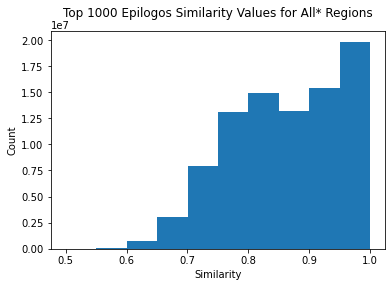

In [43]:
non_zero_regions = np.where(epi_top_1000_scaled_vals[:, 0]!=0)[0]

fig = plt.figure()
fig.patch.set_facecolor('white')

plt.hist(epi_top_1000_scaled_vals[non_zero_regions].flatten())


plt.xlabel('Similarity')
plt.ylabel('Count')
plt.title('Top 1000 Epilogos Similarity Values for All* Regions', y=1.04)

Text(0.5, 1.04, 'Top 1000 Epilogos Rescaled Similarity Values for All Regions')

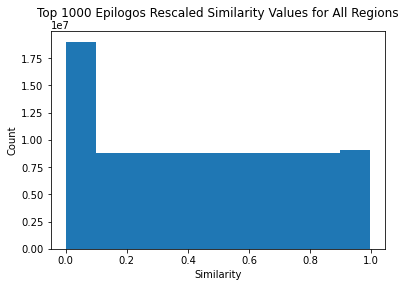

In [70]:
epi_top_1000_rescaled_vals = scale_data(epi_top_1000_scaled_vals, 1)
non_zero_regions = np.where(epi_top_1000_rescaled_vals[:, 0]!=0)[0]

fig = plt.figure()
fig.patch.set_facecolor('white')

plt.hist(epi_top_1000_rescaled_vals.flatten())


plt.xlabel('Similarity')
plt.ylabel('Count')
plt.title('Top 1000 Epilogos Rescaled Similarity Values for All Regions', y=1.04)

Text(0.5, 1.04, 'Top 1000 Epilogos Similarity Values for Region 1')

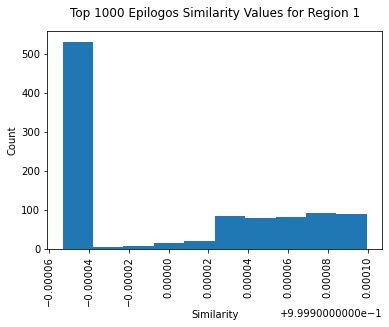

In [44]:
fig = plt.figure()
fig.patch.set_facecolor('white')

plt.hist(epi_top_1000_scaled_vals[1])

plt.xticks(rotation=90)

plt.xlabel('Similarity')
plt.ylabel('Count')
plt.title('Top 1000 Epilogos Similarity Values for Region 1', y=1.04)

In [35]:
count_path='/home/ctrader/region_similarity/data/rank_based/regions_25kb_CT20221027.epilogosmeanmax.hdf5'

#load the data
count_hdf5 = h5py.File(count_path, 'r')
epi_count_arr = count_hdf5['base_arr'][:]
count_hdf5.close()

In [36]:
epi_ranked_regions = rank_regions(epi_count_arr)
epi_sigmoid_ranks = sigmoid_func_2(epi_ranked_regions)

epi_sigmoid_ranks_max = np.max(epi_sigmoid_ranks, axis=1)

epi_max_sigmoid_a = np.vstack([epi_sigmoid_ranks_max]*1000).T
epi_max_sigmoid_b = epi_sigmoid_ranks_max[epi_top_1000_similar_regions]

epi_max_sigmoid_to_scale = (epi_max_sigmoid_a + epi_max_sigmoid_b) / 2
epi_top_1000_sigmoid_scaled_vals = epi_top_1000_scaled_vals * epi_max_sigmoid_to_scale

In [39]:
np.min(epi_top_1000_sigmoid_scaled_vals[epi_top_1000_sigmoid_scaled_vals>0])

0.03968982033688406

In [12]:
sigmoideuc_path = '/home/ctrader/region_similarity/data/rank_based/regions_25kb_CT20221101.epilogossigmoideuc.hdf5'
sigmoideuc_hdf5 = h5py.File(sigmoideuc_path, 'r')
epi_top_1000_sigmoid_scaled_vals = sigmoideuc_hdf5['top_1000_sigmoid_scaled_vals'][:]
epi_sigmoid_ranks = sigmoideuc_hdf5['sigmoid_ranks'][:]
sigmoideuc_hdf5.close()

Text(0.5, 1.0, 'Epilogos Sigmoid Scaled Values')

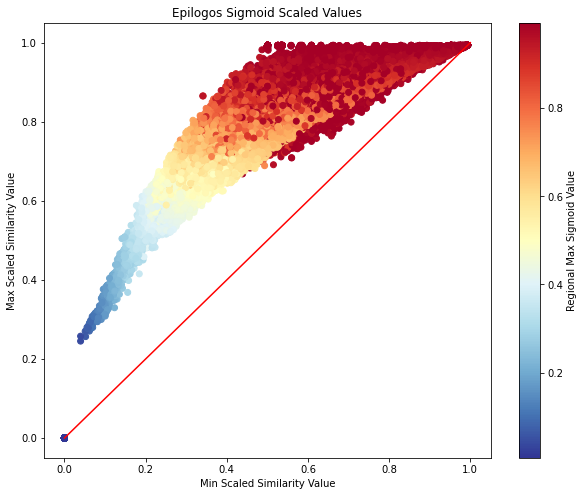

In [13]:
epi_sigmoid_ranks_max = np.max(epi_sigmoid_ranks, axis=1)

epi_min_top1000_per_region = np.min(epi_top_1000_sigmoid_scaled_vals, axis=1)
epi_max_top1000_per_region = np.max(epi_top_1000_sigmoid_scaled_vals, axis=1)

cm = plt.cm.get_cmap('RdYlBu_r')

fig = plt.figure(figsize=(10, 8))
fig.patch.set_facecolor('white')

s = plt.scatter(epi_min_top1000_per_region, epi_max_top1000_per_region, c=epi_sigmoid_ranks_max, cmap=cm)
plt.plot([0, 1], [0, 1], color='r')
plt.colorbar(s).set_label('Regional Max Sigmoid Value')


plt.xlabel('Min Scaled Similarity Value')
plt.ylabel('Max Scaled Similarity Value')
plt.title('Epilogos Sigmoid Scaled Values')

Text(0.5, 1.0, 'Top Sigmoid Scaled Epilogos Similarity Score for each Region')

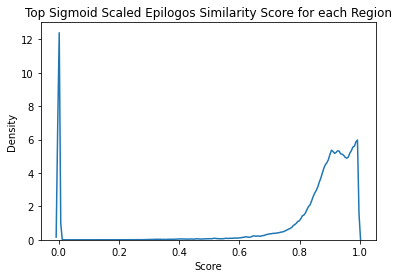

In [22]:
fig = plt.figure()
fig.patch.set_facecolor('white')

sns.kdeplot(epi_max_top1000_per_region, bw_adjust=0.1)

plt.xlabel('Score')
plt.title('Top Sigmoid Scaled Epilogos Similarity Score for each Region')

In [74]:
sigmoideuc_path = '/home/ctrader/region_similarity/data/rank_based/regions_25kb_CT20221101.epilogossigmoideuc.hdf5'
sigmoideuc_hdf5 = h5py.File(sigmoideuc_path, 'r')
epi_top_1000_sigmoid_scaled_vals = sigmoideuc_hdf5['top_1000_sigmoid_scaled_vals'][:]
epi_sigmoid_ranks = sigmoideuc_hdf5['sigmoid_ranks'][:]
sigmoideuc_hdf5.close()

In [75]:
epi_sigmoid_ranks_max = np.max(epi_sigmoid_ranks, axis=1)
epi_top_1000_sigmoid_scaled_vals_rescaled = scale_data(epi_top_1000_sigmoid_scaled_vals, 1)

Text(0.5, 1.0, 'Epilogos Sigmoid Scaled Values Rescaled')

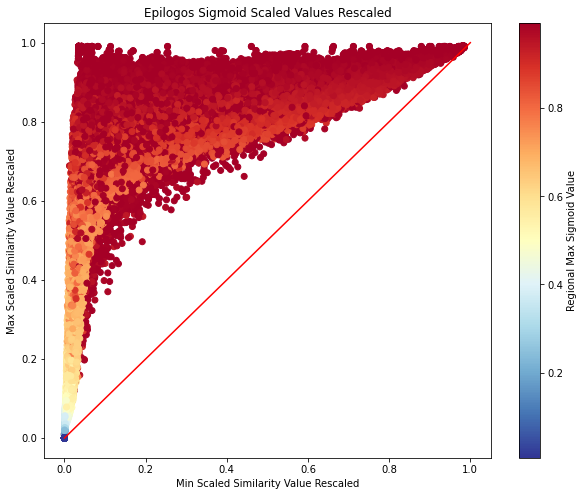

In [76]:
min_top1000_per_region = np.min(epi_top_1000_sigmoid_scaled_vals_rescaled, axis=1)
max_top1000_per_region = np.max(epi_top_1000_sigmoid_scaled_vals_rescaled, axis=1)

cm = plt.cm.get_cmap('RdYlBu_r')

fig = plt.figure(figsize=(10, 8))
fig.patch.set_facecolor('white')

s = plt.scatter(min_top1000_per_region, max_top1000_per_region, c=epi_sigmoid_ranks_max, cmap=cm)
plt.plot([0, 1], [0, 1], color='r')
plt.colorbar(s).set_label('Regional Max Sigmoid Value')


plt.xlabel('Min Scaled Similarity Value Rescaled')
plt.ylabel('Max Scaled Similarity Value Rescaled')
plt.title('Epilogos Sigmoid Scaled Values Rescaled')

**Comparing scores from each metric to fusion scores**

In [50]:
sigmoideuc_path = '/home/ctrader/region_similarity/data/rank_based/regions_25kb_CT20221101.DHSsigmoideuc.hdf5'
sigmoideuc_hdf5 = h5py.File(sigmoideuc_path, 'r')
DHS_top_1000_sigmoid_scaled_vals = sigmoideuc_hdf5['top_1000_sigmoid_scaled_vals'][:]
DHS_top_1000_similar_regions = sigmoideuc_hdf5['top_1000_similar_regions'][:]
sigmoideuc_hdf5.close()

In [51]:
sigmoideuc_path = '/home/ctrader/region_similarity/data/rank_based/regions_25kb_CT20221101.TFsigmoideuc.hdf5'
sigmoideuc_hdf5 = h5py.File(sigmoideuc_path, 'r')
TF_top_1000_sigmoid_scaled_vals = sigmoideuc_hdf5['top_1000_sigmoid_scaled_vals'][:]
TF_top_1000_similar_regions = sigmoideuc_hdf5['top_1000_similar_regions'][:]
sigmoideuc_hdf5.close()

In [52]:
sigmoideuc_path = '/home/ctrader/region_similarity/data/rank_based/regions_25kb_CT20221101.epilogossigmoideuc.hdf5'
sigmoideuc_hdf5 = h5py.File(sigmoideuc_path, 'r')
epi_top_1000_sigmoid_scaled_vals = sigmoideuc_hdf5['top_1000_sigmoid_scaled_vals'][:]
epi_top_1000_similar_regions = sigmoideuc_hdf5['top_1000_similar_regions'][:]
sigmoideuc_hdf5.close()

In [204]:
epi_top_1000_sigmoid_scaled_vals[:, 0]

array([0.99330715, 0.9933068 , 0.99330715, ..., 0.        , 0.        ,
       0.        ])

In [12]:
#for each metric, finding the top score and region
DHS_top_sigmoid_scaled_val = DHS_top_1000_sigmoid_scaled_vals[:, 0]
DHS_top_similar_region = DHS_top_1000_similar_regions[:, 0]

TF_top_sigmoid_scaled_val = TF_top_1000_sigmoid_scaled_vals[:, 0]
TF_top_similar_region = TF_top_1000_similar_regions[:, 0]

epi_top_sigmoid_scaled_val = epi_top_1000_sigmoid_scaled_vals[:, 0]
epi_top_similar_region = epi_top_1000_similar_regions[:, 0]

In [44]:
DHS_top_similar_region

array([65758, 31698, 44104, ...,     0,     0,     0])

In [143]:
num_regions = len(DHS_top_1000_sigmoid_scaled_vals)

DHS_top_region_fusion = np.array([])
TF_top_region_fusion = np.array([])
epi_top_region_fusion = np.array([])

for i in range(num_regions):
    DHS_arr = np.zeros(num_regions)
    TF_arr = np.zeros(num_regions)
    epi_arr = np.zeros(num_regions)

    #setting similarity values for each region
    DHS_arr[DHS_top_1000_similar_regions[i]] = DHS_top_1000_sigmoid_scaled_vals[i]
    TF_arr[TF_top_1000_similar_regions[i]] = TF_top_1000_sigmoid_scaled_vals[i]
    epi_arr[epi_top_1000_similar_regions[i]] = epi_top_1000_sigmoid_scaled_vals[i]
    
    #fusion score
    fusion_i = 1 - ((1 - DHS_arr) * (1 - TF_arr) * (1 - epi_arr))
    
    DHS_top_region_fusion = np.append(DHS_top_region_fusion, fusion_i[DHS_top_similar_region[i]])
    TF_top_region_fusion = np.append(TF_top_region_fusion, fusion_i[TF_top_similar_region[i]])
    epi_top_region_fusion = np.append(epi_top_region_fusion, fusion_i[epi_top_similar_region[i]])

Text(0.5, 0.98, 'Scores for All Query Regions and Their Most Similar Regions According to Each Metric')

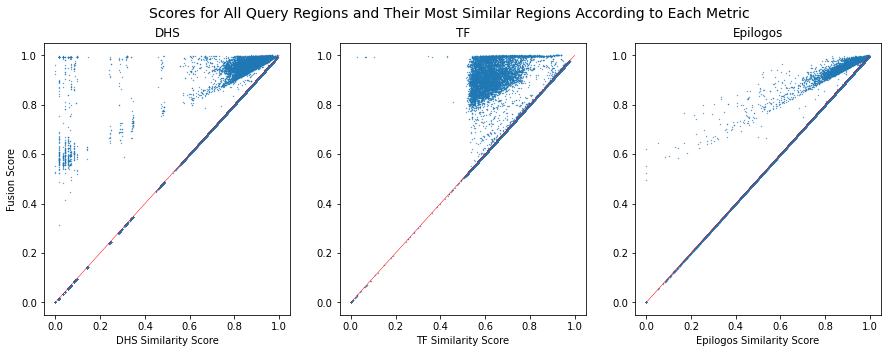

In [121]:
fig, axes = plt.subplots(ncols=3, figsize=(15, 5))
fig.patch.set_facecolor('white')


axes[0].plot([0, 1], [0, 1], color='r', linewidth=0.5)
axes[0].scatter(DHS_top_sigmoid_scaled_val, DHS_top_region_fusion, s=0.1)
axes[0].set_title('DHS')
axes[0].set_xlabel('DHS Similarity Score')

axes[1].plot([0, 1], [0, 1], color='r', linewidth=0.5)
axes[1].scatter(TF_top_sigmoid_scaled_val, TF_top_region_fusion, s=0.1)
axes[1].set_title('TF')
axes[1].set_xlabel('TF Similarity Score')

axes[2].plot([0, 1], [0, 1], color='r', linewidth=0.5)
axes[2].scatter(epi_top_sigmoid_scaled_val, epi_top_region_fusion, s=0.1)
axes[2].set_title('Epilogos')
axes[2].set_xlabel('Epilogos Similarity Score')


axes[0].set_ylabel('Fusion Score')

fig.suptitle('Scores for All Query Regions and Their Most Similar Regions According to Each Metric', fontsize=14)

In [199]:
num_regions = len(DHS_top_1000_sigmoid_scaled_vals)

DHS_num_in_top_100 = np.array([])
TF_num_in_top_100 = np.array([])
epi_num_in_top_100 = np.array([])



for i in range(num_regions):
    DHS_arr = np.zeros(num_regions)
    TF_arr = np.zeros(num_regions)
    epi_arr = np.zeros(num_regions)

    #setting similarity values for each region
    DHS_arr[DHS_top_1000_similar_regions[i]] = DHS_top_1000_sigmoid_scaled_vals[i]
    TF_arr[TF_top_1000_similar_regions[i]] = TF_top_1000_sigmoid_scaled_vals[i]
    epi_arr[epi_top_1000_similar_regions[i]] = epi_top_1000_sigmoid_scaled_vals[i]
    
    #fusion score
    fusion_i = 1 - ((1 - DHS_arr) * (1 - TF_arr) * (1 - epi_arr))
    
    #how many of top 100 are from each metric
    top_100_regions = set(np.argsort(-fusion_i)[:100])
    num_DHS_in_top = 100 - len(top_100_regions - set(DHS_top_1000_similar_regions[i][DHS_top_1000_sigmoid_scaled_vals[i] > 0]))
    num_TF_in_top = 100 - len(top_100_regions - set(TF_top_1000_similar_regions[i][TF_top_1000_sigmoid_scaled_vals[i] > 0]))
    num_epi_in_top = 100 - len(top_100_regions - set(epi_top_1000_similar_regions[i][epi_top_1000_sigmoid_scaled_vals[i] > 0]))
    
    DHS_num_in_top_100 = np.append(DHS_num_in_top_100, num_DHS_in_top)
    TF_num_in_top_100 = np.append(TF_num_in_top_100, num_TF_in_top)
    epi_num_in_top_100 = np.append(epi_num_in_top_100, num_epi_in_top)
    
DHS_num_in_top_100 = DHS_num_in_top_100 / 100
TF_num_in_top_100 = TF_num_in_top_100 / 100
epi_num_in_top_100 = epi_num_in_top_100 / 100

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/seaborn/_decorators.py:36: FutureWarning: Pass the following variables as keyword args: x, y. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  warnings.warn(


Text(0.5, 1.0, 'Contributions to Top 100 Similar Regions from each Metric for All Query Regions')

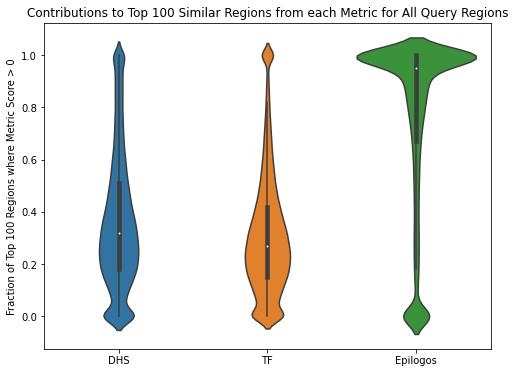

In [201]:
violin_y = np.append(np.append(DHS_num_in_top_100, TF_num_in_top_100), epi_num_in_top_100)
violin_x = np.append(np.append(np.zeros(len(DHS_num_in_top_100)), np.ones(len(TF_num_in_top_100))), np.ones(len(epi_num_in_top_100))*2)

fig = plt.figure(figsize=(8, 6))
fig.patch.set_facecolor('white')

s = sns.violinplot(violin_x, violin_y)

plt.xticks([0, 1, 2], ['DHS', 'TF', 'Epilogos'])

plt.ylabel('Fraction of Top 100 Regions where Metric Score > 0')
plt.title('Contributions to Top 100 Similar Regions from each Metric for All Query Regions')

In [56]:
num_regions = len(DHS_top_1000_sigmoid_scaled_vals)

top_100_regions_split_by_contributions = []

for i in range(num_regions):
    DHS_arr = np.zeros(num_regions)
    TF_arr = np.zeros(num_regions)
    epi_arr = np.zeros(num_regions)

    #setting similarity values for each region
    DHS_arr[DHS_top_1000_similar_regions[i]] = DHS_top_1000_sigmoid_scaled_vals[i]
    TF_arr[TF_top_1000_similar_regions[i]] = TF_top_1000_sigmoid_scaled_vals[i]
    epi_arr[epi_top_1000_similar_regions[i]] = epi_top_1000_sigmoid_scaled_vals[i]
    
    #fusion score
    fusion_i = 1 - ((1 - DHS_arr) * (1 - TF_arr) * (1 - epi_arr))
    
    #how many of top 100 are from each metric
    top_100 = np.argsort(-fusion_i)[:100]
    all3 = len(top_100[np.isin(top_100, DHS_top_1000_similar_regions[i]) & 
                       np.isin(top_100, TF_top_1000_similar_regions[i]) & 
                       np.isin(top_100, epi_top_1000_similar_regions[i])])
    notDHS = len(top_100[~np.isin(top_100, DHS_top_1000_similar_regions[i]) & 
                         np.isin(top_100, TF_top_1000_similar_regions[i]) & 
                         np.isin(top_100, epi_top_1000_similar_regions[i])])
    notTF = len(top_100[np.isin(top_100, DHS_top_1000_similar_regions[i]) & 
                        ~np.isin(top_100, TF_top_1000_similar_regions[i]) & 
                        np.isin(top_100, epi_top_1000_similar_regions[i])])
    notepi = len(top_100[np.isin(top_100, DHS_top_1000_similar_regions[i]) & 
                         np.isin(top_100, TF_top_1000_similar_regions[i]) & 
                         ~np.isin(top_100, epi_top_1000_similar_regions[i])])
    dhsonly = len(top_100[np.isin(top_100, DHS_top_1000_similar_regions[i]) & 
                          ~np.isin(top_100, TF_top_1000_similar_regions[i]) & 
                          ~np.isin(top_100, epi_top_1000_similar_regions[i])])
    TFonly = len(top_100[~np.isin(top_100, DHS_top_1000_similar_regions[i]) & 
                         np.isin(top_100, TF_top_1000_similar_regions[i]) & 
                         ~np.isin(top_100, epi_top_1000_similar_regions[i])])
    epionly = len(top_100[~np.isin(top_100, DHS_top_1000_similar_regions[i]) & 
                          ~np.isin(top_100, TF_top_1000_similar_regions[i]) & 
                          np.isin(top_100, epi_top_1000_similar_regions[i])])

    top_100_regions_split_by_contributions.append([all3, notDHS, notTF, notepi, dhsonly, TFonly, epionly])
top_100_regions_split_by_contributions = np.array(top_100_regions_split_by_contributions)

In [122]:
np.mean(top_100_regions_split_by_contributions, axis=0)

array([ 7.61961492, 21.49975159, 20.98721471,  6.29563313,  8.26385749,
        2.47358282, 32.86034533])

In [86]:
violin_y = top_100_regions_split_by_contributions.flatten('F')

In [87]:
violin_x = (np.ones(top_100_regions_split_by_contributions.shape) * np.arange(7)).flatten('F')

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/seaborn/_decorators.py:36: FutureWarning: Pass the following variables as keyword args: x, y. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  warnings.warn(


Text(0.5, 1.0, 'Contributions to Top 100 Similar Regions from each Metric Combination for All Query Regions')

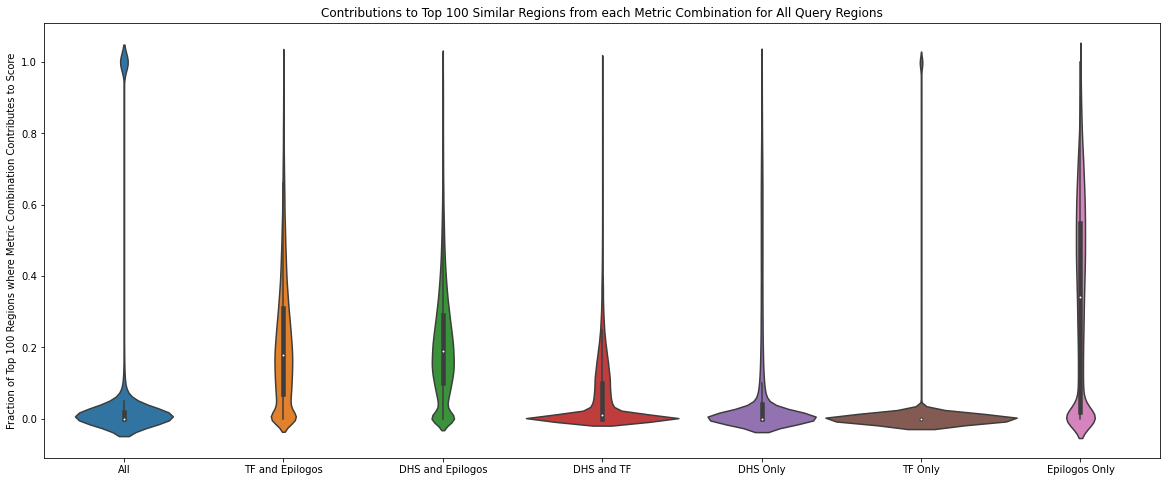

In [113]:
violin_y = top_100_regions_split_by_contributions.flatten('F') / 100
violin_x = (np.ones(top_100_regions_split_by_contributions.shape) * np.arange(7)).flatten('F')

fig = plt.figure(figsize=(20, 8))
fig.patch.set_facecolor('white')

s = sns.violinplot(violin_x, violin_y, width=1.2)

plt.xticks(np.arange(7), 
           ['All', 'TF and Epilogos', 'DHS and Epilogos', 'DHS and TF', 'DHS Only', 'TF Only', 'Epilogos Only'])

plt.ylabel('Fraction of Top 100 Regions where Metric Combination Contributes to Score')
plt.title('Contributions to Top 100 Similar Regions from each Metric Combination for All Query Regions')

**Scratch work below**

**Jaccard similarity with a rank scaling**

In [16]:
ranked_regions

array([[   0. ,    0. ,    0. , ...,    0. ,    0. ,    0. ],
       [   0. ,    0. ,    0. , ...,    0. ,    0. ,    0. ],
       [   0. ,    0. ,    0. , ..., 6829.5,    0. ,    0. ],
       ...,
       [   0. ,    0. ,    0. , ...,    0. ,    0. ,    0. ],
       [   0. ,    0. ,    0. , ...,    0. ,    0. ,    0. ],
       [   0. ,    0. ,    0. , ...,    0. ,    0. ,    0. ]])

In [17]:
sigmoid_ranks[:2]

array([[0.00669285, 0.00669285, 0.00669285, 0.00669285, 0.00669285,
        0.00669285, 0.00669285, 0.00669285, 0.00669285, 0.00669285,
        0.00669285, 0.00669285, 0.00669285, 0.00669285, 0.00669285,
        0.00669285],
       [0.00669285, 0.00669285, 0.00669285, 0.00669285, 0.00669285,
        0.00669285, 0.01386715, 0.00669285, 0.03255043, 0.0143203 ,
        0.00669285, 0.00669285, 0.00669285, 0.00669285, 0.00669285,
        0.00669285]])

In [91]:
#euclidean distance matrix
count_arr_bin = np.where(count_arr > 0, 1, 0)
jaccard_m_count = squareform(pdist(count_arr_bin[:10000], metric='jaccard'))

In [100]:
count_arr[[1, 9999], :]

array([[0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0],
       [0, 0, 1, 2, 1, 5, 1, 1, 0, 4, 0, 1, 1, 4, 1, 0]])

In [101]:
ranked_regions[[1, 9999], :]

array([[    0. ,     0. ,     0. ,     0. ,     0. ,     0. ,  5935. ,
            0. ,  9450. ,  6350. ,     0. ,     0. ,     0. ,     0. ,
            0. ,     0. ],
       [    0. ,     0. , 11036.5, 25056. , 11199. , 49512.5,  5935. ,
        11048.5,     0. , 45391. ,     0. , 12324.5,  9765. , 40908.5,
        12151.5,     0. ]])

In [105]:
##find which components there are ranks for both regions
#in those components, find absolute different in ranks
#invert so that if there is a small difference in ranks, you have a greater similarity score
np.where()
ranked_regions[1] - ranked_regions[9999]

array([     0. ,      0. , -11036.5, -25056. , -11199. , -49512.5,
            0. , -11048.5,   9450. , -39041. ,      0. , -12324.5,
        -9765. , -40908.5, -12151.5,      0. ])

In [97]:
squareform(pdist(count_arr_bin[:4], metric='jaccard'))

array([[0., 1., 1., 0.],
       [1., 0., 1., 1.],
       [1., 1., 0., 1.],
       [0., 1., 1., 0.]])

In [92]:
jaccard_m_count

array([[0.        , 1.        , 1.        , ..., 1.        , 1.        ,
        1.        ],
       [1.        , 0.        , 1.        , ..., 0.8       , 0.85714286,
        0.83333333],
       [1.        , 1.        , 0.        , ..., 0.9       , 0.84615385,
        0.81818182],
       ...,
       [1.        , 0.8       , 0.9       , ..., 0.        , 0.42857143,
        0.46153846],
       [1.        , 0.85714286, 0.84615385, ..., 0.42857143, 0.        ,
        0.15384615],
       [1.        , 0.83333333, 0.81818182, ..., 0.46153846, 0.15384615,
        0.        ]])

In [74]:
count_arr.shape

(98629, 16)

**Scaling similarity scores using sigmoid**

In [7]:
sigmoid_ranks_max = np.max(sigmoid_ranks, axis=1)

In [23]:
top_1000_scaled_vals

array([[0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [1.        , 1.        , 1.        , ..., 0.98458564, 0.98458564,
        0.98458564],
       [1.        , 1.        , 1.        , ..., 0.98332002, 0.98332002,
        0.98332002],
       ...,
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ]])

In [24]:
top_1000_similar_regions

array([[65758, 65757, 65756, ..., 64807, 64806, 64805],
       [31698, 95890, 95508, ..., 44130, 49657, 37438],
       [44104,  9273,  9314, ..., 57070, 49689, 88282],
       ...,
       [    0, 65758, 65757, ..., 64809, 64807, 64806],
       [    0, 65758, 65757, ..., 64809, 64807, 64806],
       [    0, 65758, 65757, ..., 64809, 64807, 64806]])

In [53]:
max_sigmoid_a = np.vstack([sigmoid_ranks_max]*1000).T

In [35]:
max_sigmoid_b = sigmoid_ranks_max[top_1000_similar_regions]

In [54]:
max_sigmoid_to_scale = (max_sigmoid_a + max_sigmoid_b) / 2

In [60]:
top_1000_sigmoid_scaled_vals = top_1000_scaled_vals * max_sigmoid_to_scale

In [63]:
top_1000_sigmoid_scaled_vals

array([[0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.03255043, 0.03255043, 0.03255043, ..., 0.04469982, 0.04469982,
        0.04469982],
       [0.04231042, 0.04231042, 0.04231042, ..., 0.04944096, 0.04944096,
        0.04944096],
       ...,
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ]])

0.8265123585329468

Text(0.5, 1.0, 'Sigmoid Scaled Similarity Scores Compared to Number of DHSs')

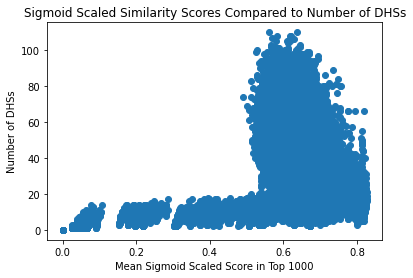

In [65]:
average_top1000_per_region_sigmoid_scaled = np.mean(top_1000_sigmoid_scaled_vals, axis=1)
num_dhs_per_region = np.sum(count_arr, axis=1)

fig = plt.figure()
fig.patch.set_facecolor('white')

plt.scatter(average_top1000_per_region_sigmoid_scaled, num_dhs_per_region)


plt.xlabel('Mean Sigmoid Scaled Score in Top 1000')
plt.ylabel('Number of DHSs')
plt.title('Sigmoid Scaled Similarity Scores Compared to Number of DHSs')

Text(0.5, 1.0, 'Smaller Average Similarity Scores for Regions with Larger Sigmoid Values')

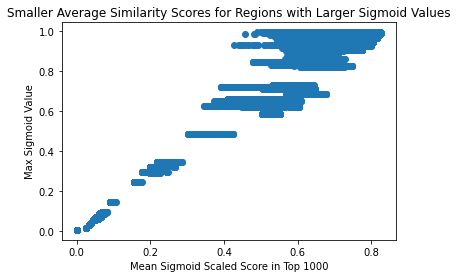

In [66]:
sigmoid_ranks_max = np.max(sigmoid_ranks, axis=1)
average_top1000_per_region_sigmoid_scaled = np.mean(top_1000_sigmoid_scaled_vals, axis=1)

fig = plt.figure()
fig.patch.set_facecolor('white')

plt.scatter(average_top1000_per_region_sigmoid_scaled, sigmoid_ranks_max)


plt.xlabel('Mean Sigmoid Scaled Score in Top 1000')
plt.ylabel('Max Sigmoid Value')
plt.title('Smaller Average Similarity Scores for Regions with Larger Sigmoid Values')

Text(0.5, 1.0, 'DHS Sigmoid Scaled Values')

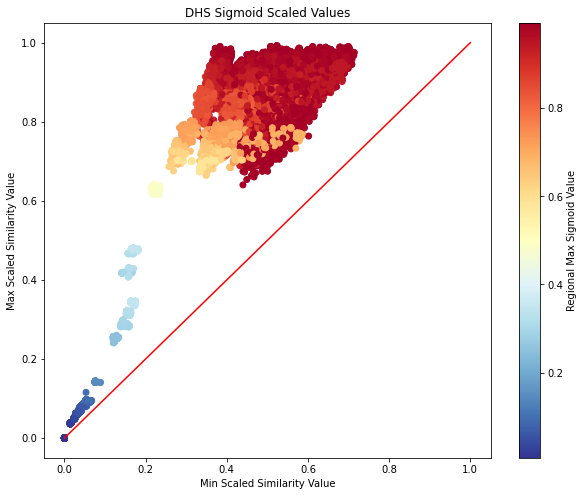

In [88]:
sigmoid_ranks_max = np.max(sigmoid_ranks, axis=1)

min_top1000_per_region = np.min(top_1000_sigmoid_scaled_vals, axis=1)
max_top1000_per_region = np.max(top_1000_sigmoid_scaled_vals, axis=1)

cm = plt.cm.get_cmap('RdYlBu_r')

fig = plt.figure(figsize=(10, 8))
fig.patch.set_facecolor('white')

s = plt.scatter(min_top1000_per_region, max_top1000_per_region, c=sigmoid_ranks_max, cmap=cm)
plt.plot([0, 1], [0, 1], color='r')
plt.colorbar(s).set_label('Regional Max Sigmoid Value')


plt.xlabel('Min Scaled Similarity Value')
plt.ylabel('Max Scaled Similarity Value')
plt.title('DHS Sigmoid Scaled Values')

**Comparing 

**STRING Distributions**

In [2]:
coex_hdf5_path = '/home/ctrader/region_similarity/data/rank_based/regions_25kb_CT20221031.coexpression_human_transferred_maxSTRINGsimilarity.hdf5'
cooccur_hdf5_path = '/home/ctrader/region_similarity/data/rank_based/regions_25kb_CT20221031.cooccurenceSTRINGsimilarity.hdf5'
database_hdf5_path = '/home/ctrader/region_similarity/data/rank_based/regions_25kb_CT20221031.database_human_transferred_maxSTRINGsimilarity.hdf5'
exper_hdf5_path = '/home/ctrader/region_similarity/data/rank_based/regions_25kb_CT20221031.experiments_human_transferred_maxSTRINGsimilarity.hdf5'
fusion_hdf5_path = '/home/ctrader/region_similarity/data/rank_based/regions_25kb_CT20221031.fusionSTRINGsimilarity.hdf5'
homology_hdf5_path = '/home/ctrader/region_similarity/data/rank_based/regions_25kb_CT20221031.homologySTRINGsimilarity.hdf5'
neigh_hdf5_path = '/home/ctrader/region_similarity/data/rank_based/regions_25kb_CT20221031.neighborhood_human_transferred_maxSTRINGsimilarity.hdf5'
textmin_hdf5_path = '/home/ctrader/region_similarity/data/rank_based/regions_25kb_CT20221031.textmining_human_transferred_maxSTRINGsimilarity.hdf5'

In [3]:
def load_STRING_hdf5_files_multiple(hdf5_path):
    #load in tracking genes
    hdf5_file = h5py.File(hdf5_path, 'r')
#     ori_genes = np.char.decode(hdf5_file['top_1000_original_genes'][roi], 'utf-8')
#     dest_genes = np.char.decode(hdf5_file['top_1000_destination_genes'][roi], 'utf-8')
#     similar_regions = hdf5_file['top_1000_similar_regions'][roi]
    scaled_vals = hdf5_file['top_1000_scaled_vals'][:]
#     STRING_vals = hdf5_file['top_1000_STRING_vals'][roi]
    hdf5_file.close()
    return scaled_vals

In [4]:
coex_scaled_vals = load_STRING_hdf5_files_multiple(coex_hdf5_path)
cooccur_scaled_vals = load_STRING_hdf5_files_multiple(cooccur_hdf5_path)
database_scaled_vals = load_STRING_hdf5_files_multiple(database_hdf5_path)
exper_scaled_vals = load_STRING_hdf5_files_multiple(exper_hdf5_path)
fusion_scaled_vals = load_STRING_hdf5_files_multiple(fusion_hdf5_path)
homology_scaled_vals = load_STRING_hdf5_files_multiple(homology_hdf5_path)
neigh_scaled_vals = load_STRING_hdf5_files_multiple(neigh_hdf5_path)
textmin_scaled_vals = load_STRING_hdf5_files_multiple(textmin_hdf5_path)

In [12]:
np.min(textmin_scaled_vals, axis=1)

(98629,)

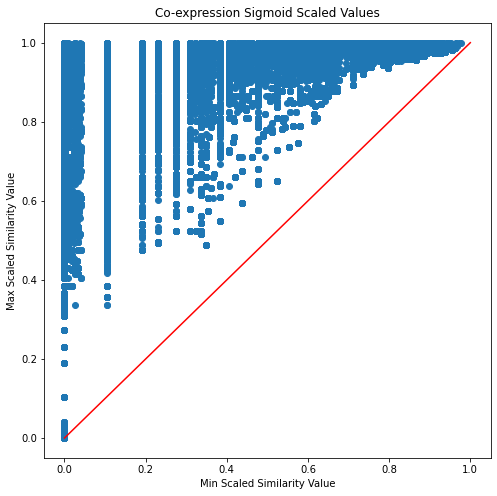

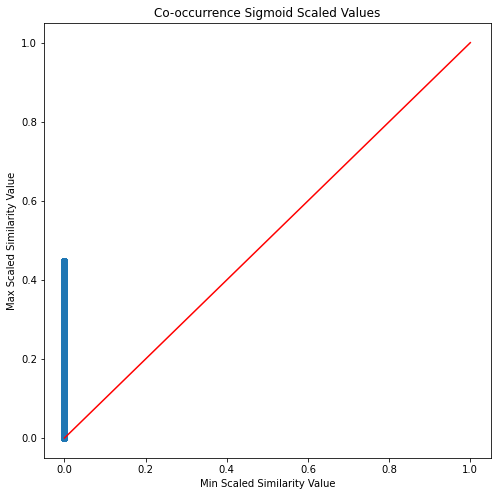

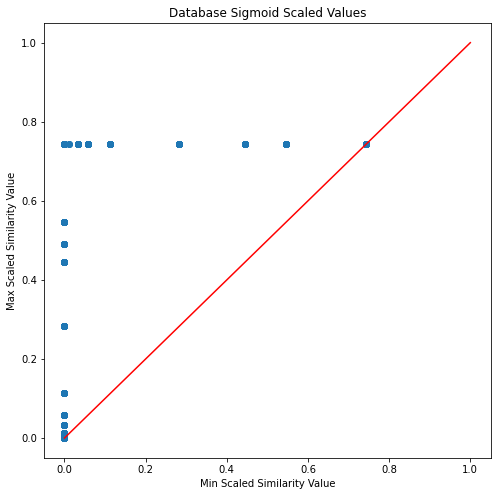

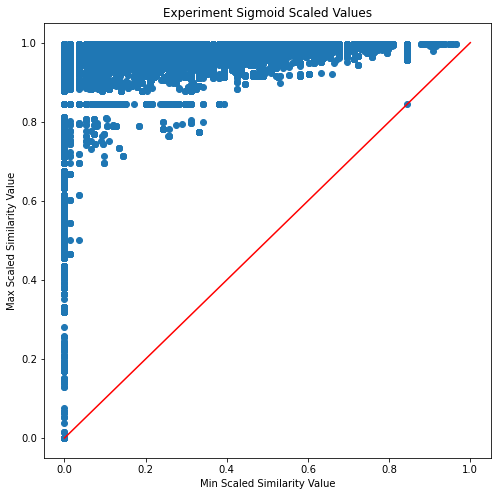

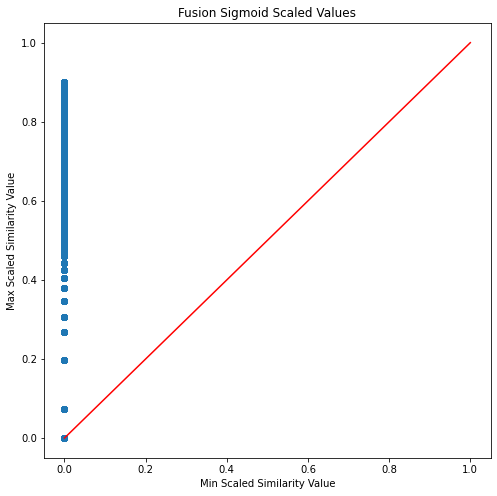

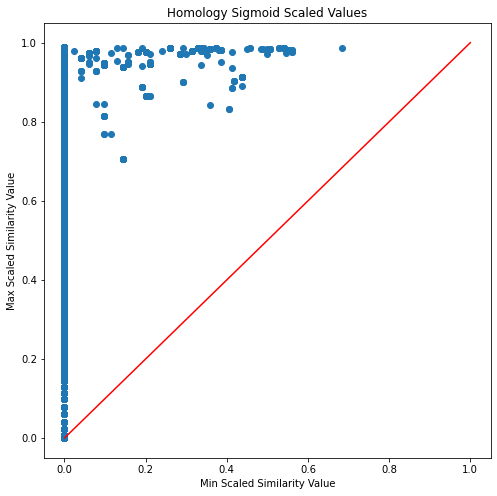

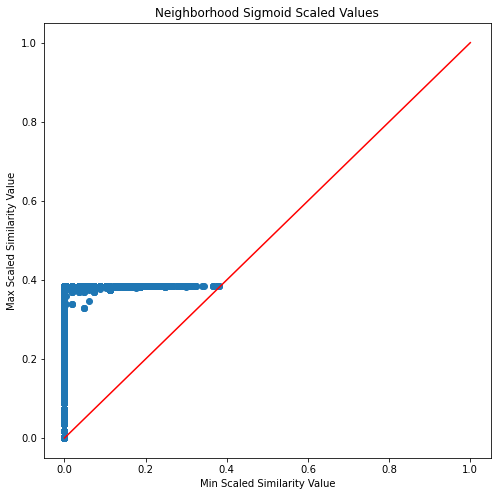

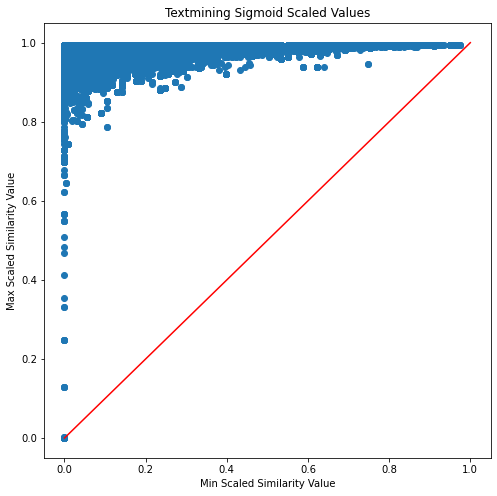

In [14]:
for arr, title in zip([coex_scaled_vals, cooccur_scaled_vals, database_scaled_vals, exper_scaled_vals, 
                       fusion_scaled_vals, homology_scaled_vals, neigh_scaled_vals, textmin_scaled_vals], 
                      ['Co-expression', 'Co-occurrence', 'Database', 'Experiment', 
                       'Fusion', 'Homology', 'Neighborhood', 'Textmining']):
    min_top1000_per_region = np.min(arr, axis=1)
    max_top1000_per_region = np.max(arr, axis=1)

    fig = plt.figure(figsize=(8, 8))
    fig.patch.set_facecolor('white')

    s = plt.scatter(min_top1000_per_region, max_top1000_per_region)
    plt.plot([0, 1], [0, 1], color='r')

    plt.xlabel('Min Scaled Similarity Value')
    plt.ylabel('Max Scaled Similarity Value')
    plt.title('%s Sigmoid Scaled Values' %(title))
    
    plt.show()

In [5]:
np.arange(0, 1.1, 0.1)

array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. ])

In [7]:
coex_scaled_vals.shape

(98629, 1000)

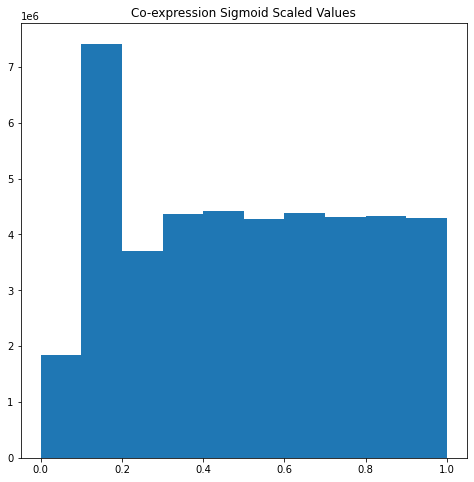

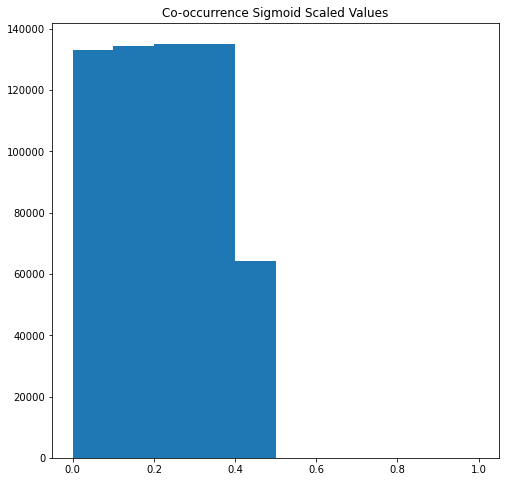

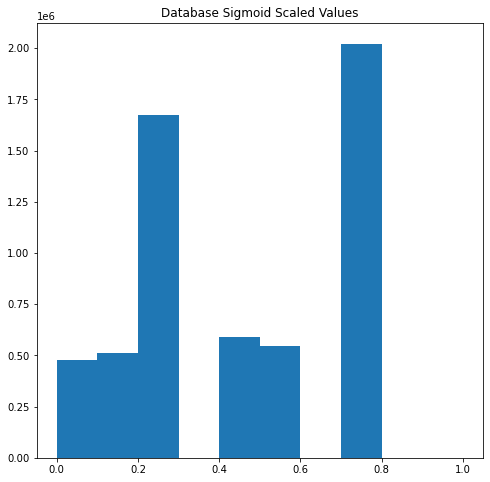

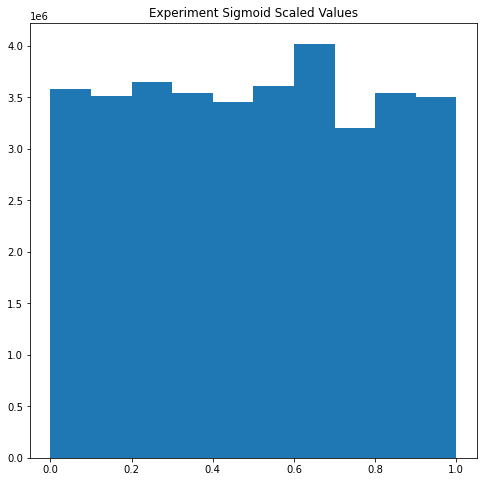

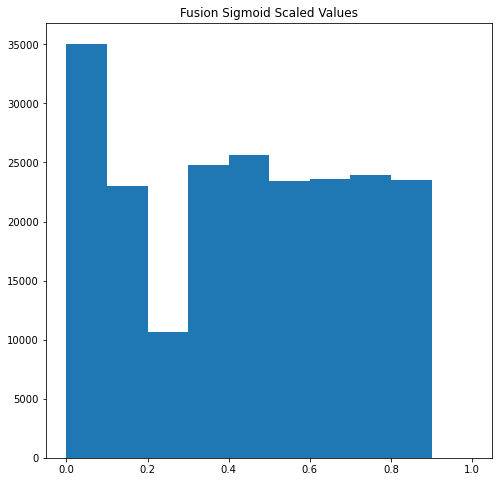

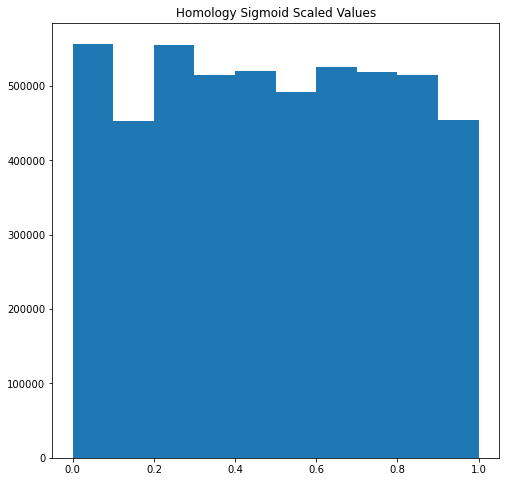

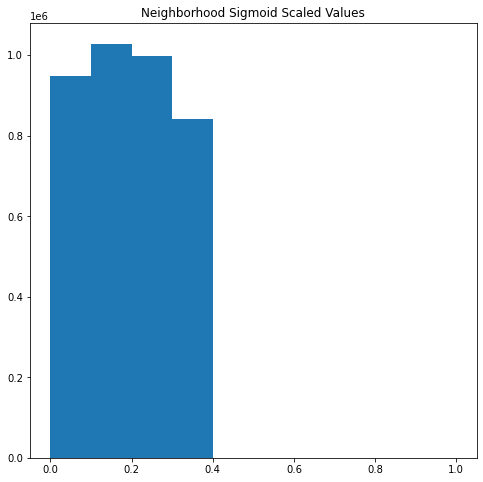

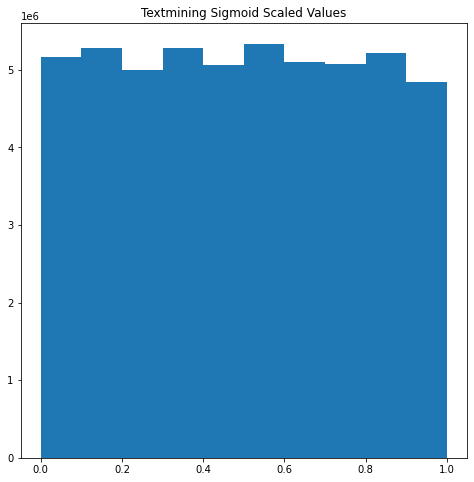

In [10]:
for arr, title in zip([coex_scaled_vals, cooccur_scaled_vals, database_scaled_vals, exper_scaled_vals, 
                       fusion_scaled_vals, homology_scaled_vals, neigh_scaled_vals, textmin_scaled_vals], 
                      ['Co-expression', 'Co-occurrence', 'Database', 'Experiment', 
                       'Fusion', 'Homology', 'Neighborhood', 'Textmining']):
    fig = plt.figure(figsize=(8, 8))
    fig.patch.set_facecolor('white')

    arr = arr.flatten()
    s = plt.hist(arr[arr!=0], bins=np.arange(0, 1.1, 0.1))
    plt.title('%s Sigmoid Scaled Values' %(title))
    
    plt.show()